# A Model of the Interest Rate Spread
## The Box–Jenkins cycle with classical and Bayesian estimation
**HS 821 · Lecture Note 12 · Topics in Time Series Econometrics**

**Sunil Paul**

This note is a case study. It reproduces the model of the interest rate spread in Enders (2015, 4th ed.), Chapter 2, Section 10, and uses it to apply every step of the toolkit developed in Lectures 9–11 to a single real series:

1. **Identification** — plot the series, read the sample ACF and PACF, and shortlist candidate models (Section 1).
2. **Classical estimation** — fit seven candidates by exact maximum likelihood and check each one (Section 2).
3. **Bayesian estimation** — re-estimate the candidates with a Gibbs sampler (AR models) and a Metropolis-within-Gibbs sampler (ARMA models), check the samplers, and use the posterior to answer questions that are awkward for classical inference (Section 3).
4. **Model comparison** — information criteria and approximate posterior model probabilities (Section 4).
5. **Forecasting** — compare classical and Bayesian forecasts out of sample, and build a Bayesian predictive fan chart (Section 5).

**Data.** Quarterly observations, 1960Q1–2012Q4 ($T=212$), on the yield of 5-year U.S. government bonds (`r5`) and the 3-month Treasury bill rate (`Tbill`). The spread is $y_t=\texttt{r5}_t-\texttt{Tbill}_t$. Both series are in the SAS data file `quarterly.sas7bdat`, which must be in the working directory.

*Notation follows Lectures 9–11: $Y_t=c+\phi_1Y_{t-1}+\cdots+\phi_pY_{t-p}+\varepsilon_t+\beta_1\varepsilon_{t-1}+\cdots+\beta_q\varepsilon_{t-q}$, $\varepsilon_t\sim\text{i.i.d. }N(0,\sigma^2)$, with mean $\mu=c/(1-\phi_1-\cdots-\phi_p)$. A "subset" model such as ARMA(2,(1,7)) keeps only the MA lags listed in brackets. Estimates may differ slightly from those in Enders, who uses conditional least squares on a sample starting in 1961Q4.*

## Setup

The plotting helpers are those of Lectures 9–11 (`resid_panel()` now counts only the *estimated* ARMA coefficients when correcting the Ljung–Box degrees of freedom, which matters for subset models, and `fan_plot()` accepts quarterly time). Three small helpers produce tables: `coef_table()`, `lb_table()` and `post_summary()`. The Gibbs sampler `gibbs_ar()` is the one from Lectures 9–11, Section 4; the Metropolis sampler for ARMA models is new and is developed in Section 3.

> **R convention.** `arima()` reports the mean $\mu$ under the label `intercept`, not the constant $c$. Its MA polynomial is $1+\beta_1L+\cdots+\beta_qL^q$, the same sign convention as ours.

In [1]:
# ------------------------------------------------------------------
# Setup: packages, plotting helpers (Lectures 9-11) and table helpers
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
  #library(haven)      # read_sas() reads .sas7bdat files (sas7bdat::read.sas7bdat() also works)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = seq_len(L), acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = seq_len(L), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
roots_plot <- function(roots, title = NULL) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots),
                      outside = ifelse(Mod(roots) > 1, "outside", "inside"))
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = outside), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red"), name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# Number of estimated ARMA coefficients (excludes the mean and coefficients fixed at zero).
n_arma <- function(fit) sum(fit$mask[seq_len(sum(fit$arma[1:4]))])

# Residual diagnostics for an arima() fit: residual series, residual ACF, and
# Ljung-Box p-values for K = n_arma + 1, ..., L with the corrected df = K - n_arma.
resid_panel <- function(fit, L = 20, title = NULL) {
  e     <- as.numeric(residuals(fit))
  fitdf <- n_arma(fit)
  lags  <- (fitdf + 1):L
  pv    <- sapply(lags, function(k)
    Box.test(e, lag = k, type = "Ljung-Box", fitdf = fitdf)$p.value)
  g1 <- ts_plot(ts(e, start = start(sp), frequency = 4), mu = 0, title = paste(title, "- residuals"))
  g2 <- sample_acf_plot(e, L = L, title = "Residual ACF")
  g3 <- ggplot(data.frame(lag = lags, p = pv), aes(lag, p)) + theme_classic() +
    geom_point(size = 2) +
    geom_hline(yintercept = 0.05, linetype = "dashed", colour = "red") +
    scale_y_continuous(limits = c(0, 1)) +
    scale_x_continuous(breaks = function(l) unique(round(pretty(l)))) +
    labs(x = "Number of lags K", y = "p-value", title = "Ljung-Box p-values")
  grid.arrange(g1, g2, g3, ncol = 3)
}

# Fan chart: last n_show observations, point forecast, 80% and 95% bands.
# t_end is the time of the last observation; freq = 4 for quarterly data.
fan_plot <- function(y, mean, lo80, hi80, lo95, hi95, n_show = 60,
                     t_end = length(y), freq = 1, title = NULL) {
  y   <- as.numeric(y); h <- length(mean)
  obs <- data.frame(time = t_end - ((n_show - 1):0) / freq, value = tail(y, n_show))
  fc  <- data.frame(time = t_end + (1:h) / freq, mean = as.numeric(mean),
                    lo80 = as.numeric(lo80), hi80 = as.numeric(hi80),
                    lo95 = as.numeric(lo95), hi95 = as.numeric(hi95))
  ggplot() + theme_classic() +
    geom_ribbon(data = fc, aes(time, ymin = lo95, ymax = hi95), fill = "grey85") +
    geom_ribbon(data = fc, aes(time, ymin = lo80, ymax = hi80), fill = "grey65") +
    geom_line(data = obs, aes(time, value)) +
    geom_line(data = fc, aes(time, mean), linetype = "dashed") +
    labs(x = "Time", y = NULL, title = title)
}

# MCMC output for one parameter: trace plot and posterior histogram
# (solid line: posterior mean; optional dashed red line: a reference value such as the MLE).
mcmc_plot <- function(draws, name, ref = NULL) {
  df <- data.frame(iter = seq_along(draws), value = as.numeric(draws))
  g1 <- ggplot(df, aes(iter, value)) + theme_classic() +
    geom_line(linewidth = 0.2) +
    labs(x = "Iteration (after burn-in)", y = name, title = paste("Trace:", name))
  g2 <- ggplot(df, aes(value)) + theme_classic() +
    geom_histogram(bins = 40, fill = "grey70", colour = "white") +
    geom_vline(xintercept = mean(df$value)) +
    labs(x = name, y = "Count", title = paste("Posterior:", name))
  if (!is.null(ref))
    g2 <- g2 + geom_vline(xintercept = ref, linetype = "dashed", colour = "red")
  list(g1, g2)
}

# Coefficient table for an arima() fit: estimates, s.e., z and two-sided p-values 2[1 - Phi(|z|)].
coef_table <- function(fit) {
  est <- coef(fit)[fit$mask]                 # estimated (not fixed) coefficients only
  se  <- sqrt(diag(fit$var.coef))
  z   <- est / se
  round(rbind(estimate = est, s.e. = se, z = z, "p-value" = 2 * pnorm(-abs(z))), 3)
}

# Ljung-Box p-values (df corrected for the estimated ARMA coefficients) for a list of fits.
lb_table <- function(fits, Ks = c(8, 12, 16, 20)) {
  out <- t(sapply(fits, function(f) sapply(Ks, function(K)
    Box.test(residuals(f), lag = K, type = "Ljung-Box", fitdf = n_arma(f))$p.value)))
  colnames(out) <- paste0("p(Q", Ks, ")")
  round(out, 3)
}

# Posterior summaries: mean, sd and 95% equal-tailed credible interval.
post_summary <- function(d) t(apply(d, 2, function(z)
  c(mean = mean(z), sd = sd(z), q2.5 = unname(quantile(z, 0.025)), q97.5 = unname(quantile(z, 0.975)))))

# 1&nbsp;&nbsp;The data and model identification

Always look at the series before modelling it.

T = 212 quarters, 1960Q1 to 2012Q4; mean 1.212, sd 0.954, min -1.19, max 3.79


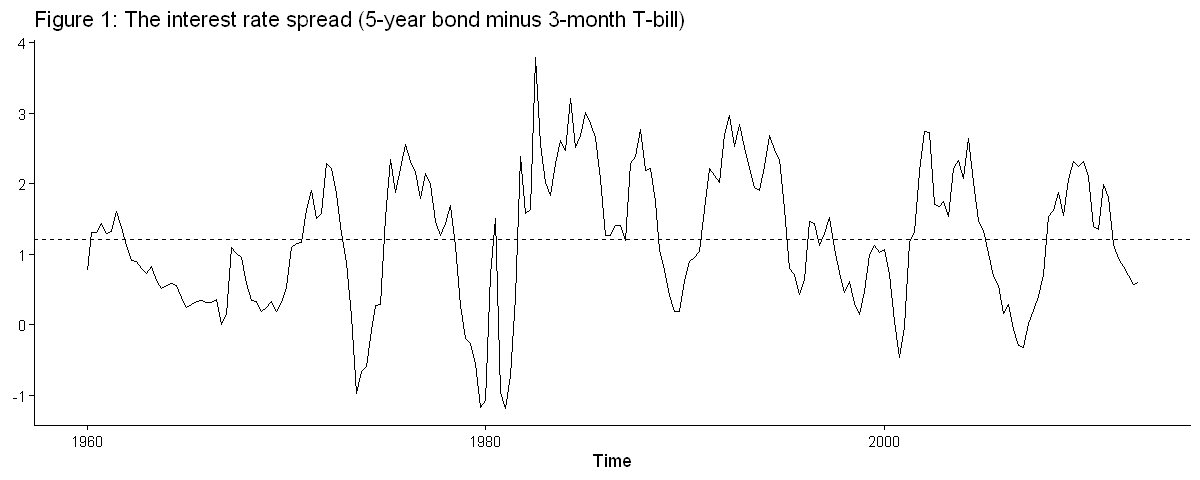

In [4]:
# Read the data and construct the spread r5 - Tbill
data1 <- read.csv("../data/quarterly.csv")
sp    <- ts(data1$r5 - data1$Tbill, start = c(1960, 1), frequency = 4)
T     <- length(sp)
cat(sprintf("T = %d quarters, %s to %s; mean %.3f, sd %.3f, min %.2f, max %.2f\n",
            T, "1960Q1", "2012Q4", mean(sp), sd(sp), min(sp), max(sp)))

options(repr.plot.height = 4)
ts_plot(sp, mu = mean(sp), title = "Figure 1: The interest rate spread (5-year bond minus 3-month T-bill)")
options(repr.plot.height = 6)

**Reading the graph.**

- The series is persistent: it stays above or below its mean (dashed line) for several years at a time.
- There is no visible trend, and no obvious break in the mean, so we treat the spread as covariance stationary. (Unit-root tests, which make this formal, come in a later lecture.)
- The series is noticeably more volatile in the late 1970s and early 1980s, and it has several sharp jumps. Both are warnings about the Gaussian, constant-variance assumptions; we return to them in Section 6.

**The sample correlogram.** Approximate 95% bands for individual autocorrelations are $\pm2/\sqrt T=\pm0.137$. The Ljung–Box statistic $Q(K)$ tests $\rho_1=\cdots=\rho_K=0$ jointly; on the raw series no degrees-of-freedom correction is needed.

Bands: +/- 2/sqrt(T) = +/- 0.137


,1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.86,0.68,0.55,0.41,0.28,0.15,0.07,0.04,-0.03,-0.13,-0.20,-0.22
PACF,0.86,-0.21,0.11,-0.18,-0.01,-0.14,0.14,0.01,-0.18,-0.12,-0.04,0.08
Q,157.69,256.67,322.03,358.66,375.68,380.57,381.69,382.04,382.27,385.90,394.72,405.84
p-value,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


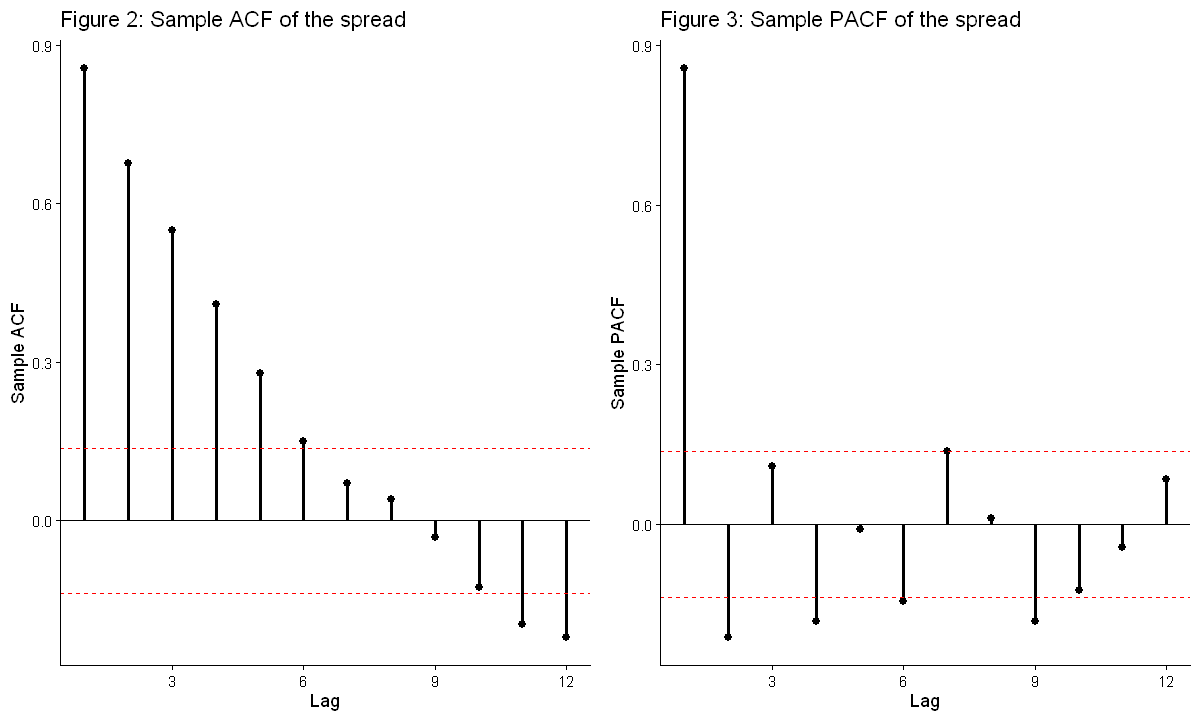

In [5]:
# Sample ACF, PACF and Ljung-Box Q(K) for K = 1, ..., 12
L    <- 12
sacf <- acf(sp,  plot = FALSE, lag.max = L)$acf[-1]
spac <- pacf(sp, plot = FALSE, lag.max = L)$acf
Qs   <- sapply(1:L, function(K) Box.test(sp, lag = K, type = "Ljung-Box")$statistic)
tab1 <- rbind(ACF = sacf, PACF = spac, Q = Qs,
              "p-value" = sapply(1:L, function(K) Box.test(sp, lag = K, type = "Ljung-Box")$p.value))
colnames(tab1) <- 1:L
cat(sprintf("Bands: +/- 2/sqrt(T) = +/- %.3f\n", 2 / sqrt(T)))
round(tab1, 2)

grid.arrange(sample_acf_plot(sp,  L = L, title = "Figure 2: Sample ACF of the spread"),
             sample_pacf_plot(sp, L = L, title = "Figure 3: Sample PACF of the spread"),
             ncol = 2)

**Reading the correlogram.**

- The ACF decays steadily to near zero by lag 8 and then turns mildly negative (about $-0.2$ at lags 11–12, a hint of a long cycle). The decay is fast enough that a time-varying mean is not a concern.
- A pure MA($q$) would show an ACF that **cuts off** after lag $q$; there is no cut-off, so pure MA models are ruled out.
- An AR(1) would have an ACF that decays geometrically, $\rho_j=\rho_1^j$. With $\hat\rho_1=0.86$ that would give $\hat\rho_2\approx0.74$ and $\hat\rho_3\approx0.64$; the sample values 0.68 and 0.55 decay faster, so a pure AR(1) is unlikely.
- The PACF has $\hat\phi_{11}=0.86$, $\hat\phi_{22}=-0.21$, $\hat\phi_{44}=-0.18$, $\hat\phi_{66}=-0.14$, $\hat\phi_{77}=0.14$ and $\hat\phi_{99}=-0.18$ on or beyond the bands. If the spread were a pure AR($p$), $p$ could be as high as six or seven.
- The first seven partial autocorrelations alternate in sign. An oscillating, decaying PACF is the fingerprint of an MA component with a positive coefficient (Lectures 6–8).
- The Ljung–Box statistics reject white noise overwhelmingly at every $K$.

Because both the ACF and the PACF decay, and several PACF spikes are only marginal, the correlogram is ambiguous. That is typical of real data. We carry several candidates forward: long autoregressions — AR(7), AR(6) and the subset AR(1,2,7) — the parsimonious AR(2), and mixed models — ARMA(1,1), ARMA(2,1) and ARMA(2,(1,7)).

> **Two cautions from Lectures 9–11.** (i) With twelve lags and 5% bands, one spike crossing the bands by chance is normal. (ii) Sample autocorrelations of a persistent series are correlated across lags, so the sample ACF looks smoother than its population counterpart. Do not chase isolated spikes at uninterpretable lags.

# 2&nbsp;&nbsp;Classical estimation: exact maximum likelihood

All seven candidates are estimated by **exact Gaussian maximum likelihood** (`arima(..., method = "ML")`) on the full sample. Exact ML uses all $T$ observations for every model, so log-likelihoods, AIC and BIC are directly comparable across models (Lectures 9–11, Section 5, rule 1). For each model we report:

- coefficients, standard errors from the Hessian, $z=\hat\theta/\operatorname{se}(\hat\theta)$, and **two-sided** $p$-values $2[1-\Phi(|z|)]$;
- the moduli of the inverse AR roots (all below one for a stationary model) and, for ARMA models, of the inverse MA roots (below one for invertibility);
- the residual diagnostics of `resid_panel()`: residual series, residual ACF, and Ljung–Box $p$-values with $K-n$ degrees of freedom, where $n$ is the number of estimated ARMA coefficients.

A small reporting function avoids repeating the same code seven times.

In [6]:
# Report an arima() fit: coefficient table, inverse-root moduli, log-likelihood, AIC, BIC
report <- function(fit, name) {
  cat("==", name, "==\n"); print(coef_table(fit))
  p <- fit$arma[1]; q <- fit$arma[2]; cf <- coef(fit)
  if (p > 0) cat("Moduli of inverse AR roots:", round(sort(Mod(1 / polyroot(c(1, -cf[1:p]))), decreasing = TRUE), 3), "\n")
  if (q > 0) cat("Moduli of inverse MA roots:", round(sort(Mod(1 / polyroot(c(1,  cf[p + 1:q]))), decreasing = TRUE), 3), "\n")
  cat(sprintf("log-likelihood %.2f | AIC %.2f | BIC %.2f | sigma2 %.4f\n", fit$loglik, AIC(fit), BIC(fit), fit$sigma2))
}
fits <- list()

## Model 1: AR(7)

== AR(7) ==
            ar1    ar2   ar3    ar4   ar5    ar6   ar7 intercept
estimate  1.106 -0.444 0.389 -0.290 0.216 -0.293 0.133     1.197
s.e.      0.068  0.100 0.104  0.105 0.103  0.099 0.068     0.169
z        16.255 -4.426 3.749 -2.760 2.091 -2.945 1.966     7.087
p-value   0.000  0.000 0.000  0.006 0.037  0.003 0.049     0.000
Moduli of inverse AR roots: 0.764 0.764 0.757 0.757 0.75 0.75 0.704 
log-likelihood -135.66 | AIC 289.32 | BIC 319.53 | sigma2 0.2087


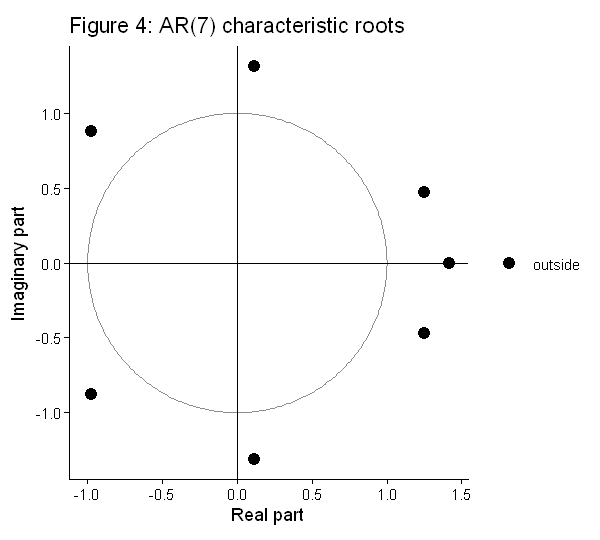

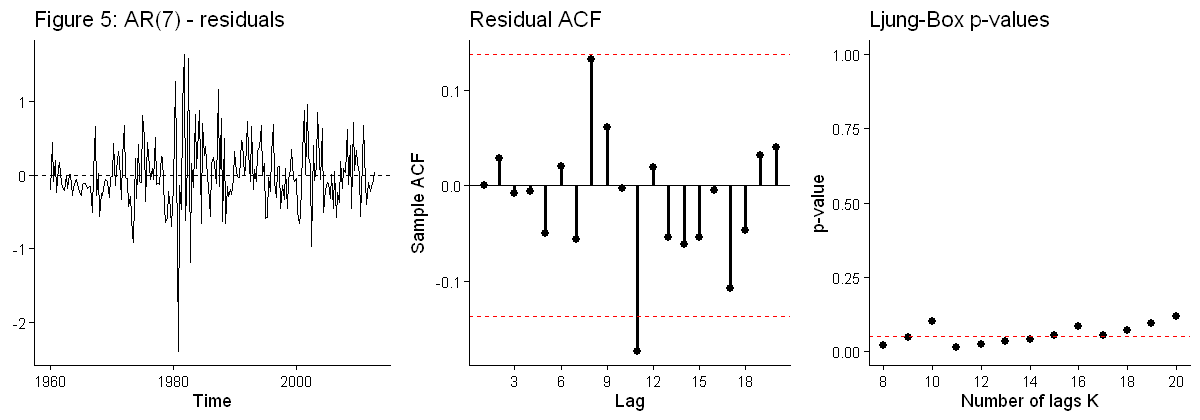

In [7]:
fits[["AR(7)"]] <- arima(sp, order = c(7, 0, 0), method = "ML")
report(fits[["AR(7)"]], "AR(7)")

options(repr.plot.width = 5, repr.plot.height = 4.5)
roots_plot(polyroot(c(1, -coef(fits[["AR(7)"]])[1:7])), title = "Figure 4: AR(7) characteristic roots")
options(repr.plot.width = 10, repr.plot.height = 3.5)
resid_panel(fits[["AR(7)"]], title = "Figure 5: AR(7)")
options(repr.plot.height = 6)

**Reading the output.**

- All seven characteristic roots lie outside the unit circle (equivalently, all inverse roots are inside it), so the estimated AR(7) is stationary.
- Every coefficient is significant at the 5% level, although $\phi_5$ and $\phi_7$ only just ($p\approx0.04$ and $0.05$). Notice the alternating signs from lag 2 onwards, with $\hat\phi_3\approx-\hat\phi_4$ and $\hat\phi_5\approx-\hat\phi_6$: the long lags partly cancel each other.
- `arima()` reports the mean $\hat\mu\approx1.20$; the constant is $\hat c=\hat\mu(1-\sum_i\hat\phi_i)$.
- The residual ACF has its largest spikes at lag 8 (just inside the band) and lag 11 (just outside). With seven estimated coefficients the Ljung–Box test for $K=8$ has only one degree of freedom; the corrected $p$-values are mostly between 0.01 and 0.05 for $K=8$ to 14 and rise above 0.05 for larger $K$. The AR(7) is borderline. If we had used $K$ instead of $K-7$ degrees of freedom (as some software does by default), every $p$-value would exceed 0.3 — **for long autoregressions the correction matters.**

Since $\phi_7$ is only marginally significant, a natural next step is to drop the seventh lag.

## Model 2: AR(6)

== AR(6) ==
            ar1    ar2   ar3    ar4   ar5    ar6 intercept
estimate  1.086 -0.422 0.356 -0.241 0.159 -0.148     1.197
s.e.      0.068  0.101 0.103  0.103 0.100  0.067     0.149
z        15.989 -4.194 3.446 -2.343 1.587 -2.195     8.021
p-value   0.000  0.000 0.001  0.019 0.113  0.028     0.000
Moduli of inverse AR roots: 0.849 0.849 0.676 0.676 0.67 0.67 
log-likelihood -137.57 | AIC 291.14 | BIC 318.00 | sigma2 0.2126


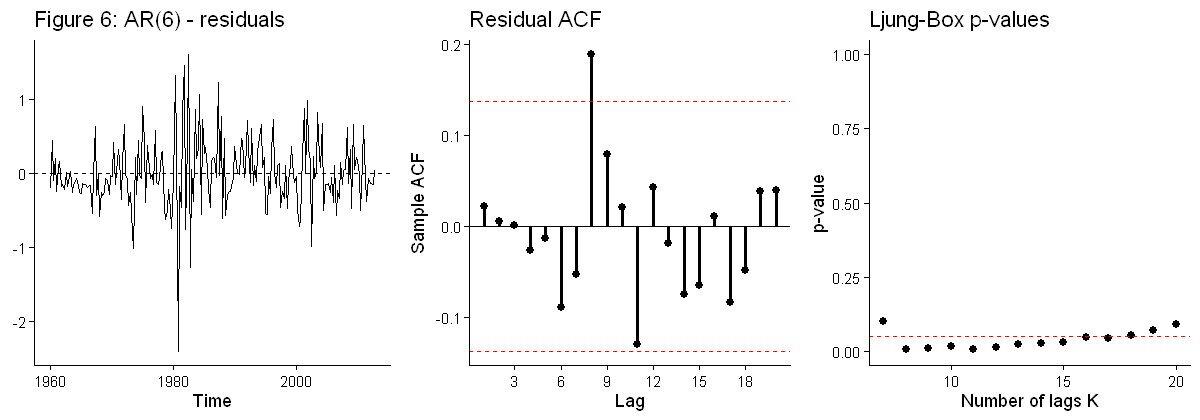

In [8]:
fits[["AR(6)"]] <- arima(sp, order = c(6, 0, 0), method = "ML")
report(fits[["AR(6)"]], "AR(6)")
options(repr.plot.height = 3.5)
resid_panel(fits[["AR(6)"]], title = "Figure 6: AR(6)")
options(repr.plot.height = 6)

**Reading the output.** The AR(6) is stationary and all coefficients except $\phi_5$ are significant. It is generally not a good idea to drop an *intermediate* lag because its $t$-statistic is small: the lagged values of a persistent series are highly correlated with each other, so individual $t$-statistics are a poor guide to which lags matter (Section 3.3 shows a better way). The residual diagnostics are worse than for the AR(7): dropping the seventh lag leaves a clear spike at lag 8, and the corrected Ljung–Box $p$-values are below 5% for $K=8$ to 16.

Comparing the two by information criteria (smaller is better), AIC prefers the AR(7) and BIC — with its heavier penalty — prefers the more parsimonious AR(6). The full comparison is in Section 4.

## Model 3: AR(2)

Let us try a very parsimonious model.

== AR(2) ==
            ar1    ar2 intercept
estimate  1.041 -0.216     1.193
s.e.      0.067  0.067     0.185
z        15.546 -3.221     6.461
p-value   0.000  0.001     0.000
Moduli of inverse AR roots: 0.755 0.286 
log-likelihood -145.01 | AIC 298.02 | BIC 311.45 | sigma2 0.2284


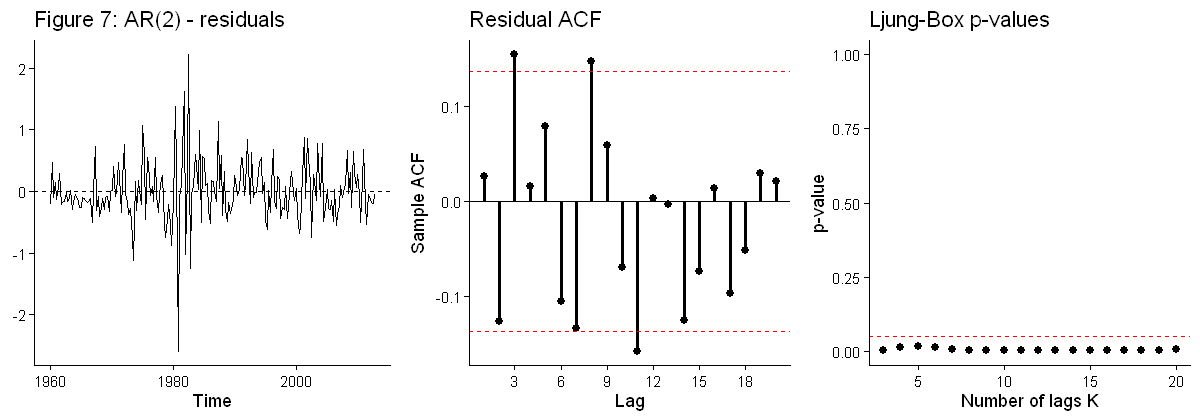

In [9]:
fits[["AR(2)"]] <- arima(sp, order = c(2, 0, 0), method = "ML")
report(fits[["AR(2)"]], "AR(2)")
options(repr.plot.height = 3.5)
resid_panel(fits[["AR(2)"]], title = "Figure 7: AR(2)")
options(repr.plot.height = 6)

**Reading the output.** The AR(2) is stationary, both coefficients are highly significant, and its BIC is lower than that of the AR(6) and AR(7). But the residuals are clearly not white noise: there are spikes at lags 3 and 8 (and 11), and the Ljung–Box test rejects at every $K$. **A model that fails diagnostic checks is eliminated, however good its information criterion.**

## Model 4: subset AR(1,2,7)

In the AR(7), $\hat\phi_3+\hat\phi_4\approx0$ and $\hat\phi_5+\hat\phi_6\approx0$. One might try to keep lags 1, 2 and 7 only, by fixing $\phi_3=\cdots=\phi_6=0$ through the `fixed` argument (`NA` marks a free parameter; `transform.pars = FALSE` is required when AR coefficients are fixed).

== AR(1,2,7) ==
            ar1    ar2    ar7 intercept
estimate  1.031 -0.199 -0.029     1.195
s.e.      0.068  0.070  0.036     0.165
z        15.162 -2.835 -0.813     7.265
p-value   0.000  0.005  0.416     0.000
Moduli of inverse AR roots: 0.785 0.785 0.595 0.595 0.519 0.519 0.498 
log-likelihood -144.68 | AIC 299.36 | BIC 316.14 | sigma2 0.2277


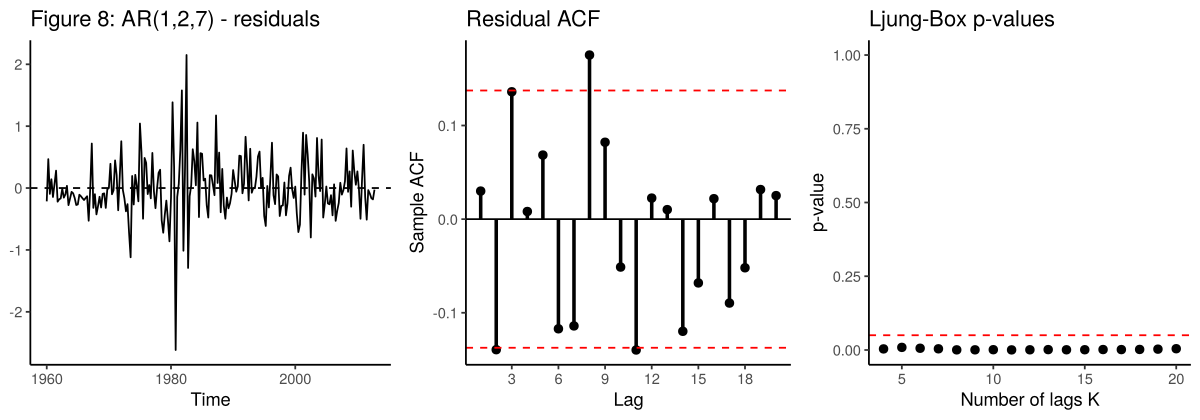

In [8]:
fits[["AR(1,2,7)"]] <- arima(sp, order = c(7, 0, 0), fixed = c(NA, NA, 0, 0, 0, 0, NA, NA),
                             transform.pars = FALSE, method = "ML")
report(fits[["AR(1,2,7)"]], "AR(1,2,7)")
options(repr.plot.height = 3.5)
resid_panel(fits[["AR(1,2,7)"]], title = "Figure 8: AR(1,2,7)")
options(repr.plot.height = 6)

**Reading the output.** Once lags 3–6 are removed, $\hat\phi_7$ becomes small and insignificant, and the model is essentially the AR(2) — with the same residual autocorrelation and the same rejection by the Ljung–Box test. The "cancelling" lags of the AR(7) were not redundant: together they carry the dynamics that the AR(2) misses. This model is eliminated too.

The long autoregressions fit reasonably well, but a mixed model may capture the same dynamics with fewer parameters. The decaying ACF together with the oscillating PACF points to an ARMA model.

## Model 5: ARMA(1,1)

== ARMA(1,1) ==
            ar1   ma1 intercept
estimate  0.757 0.377     1.193
s.e.      0.054 0.095     0.181
z        13.984 3.961     6.581
p-value   0.000 0.000     0.000
Moduli of inverse AR roots: 0.757 
Moduli of inverse MA roots: 0.377 
log-likelihood -142.75 | AIC 293.50 | BIC 306.92 | sigma2 0.2235


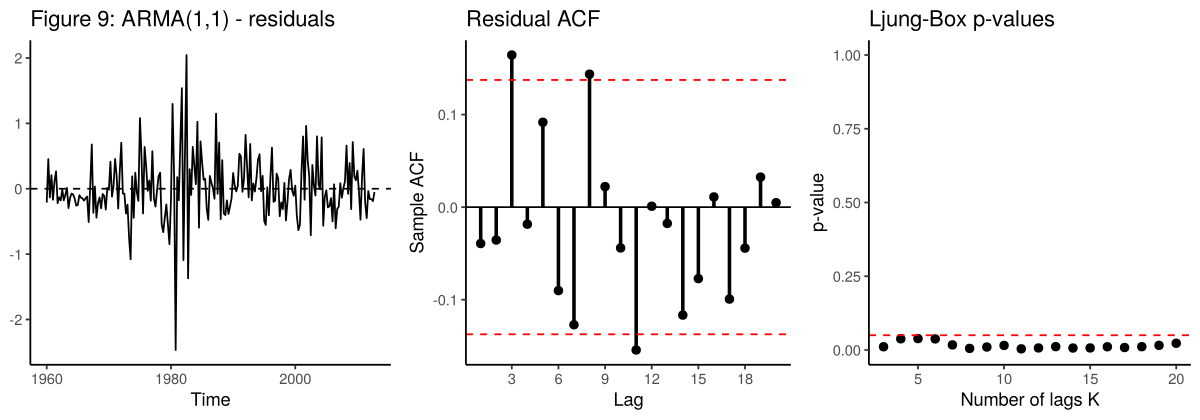

In [9]:
fits[["ARMA(1,1)"]] <- arima(sp, order = c(1, 0, 1), method = "ML")
report(fits[["ARMA(1,1)"]], "ARMA(1,1)")
options(repr.plot.height = 3.5)
resid_panel(fits[["ARMA(1,1)"]], title = "Figure 9: ARMA(1,1)")
options(repr.plot.height = 6)

**Reading the output.** Both coefficients are well inside the unit interval ($\hat\phi\approx0.76$, $\hat\beta\approx0.38$), so the model is stationary and invertible, and with only three parameters its BIC is lower than that of any autoregression so far. But the residuals still show spikes at lags 3 and 8, and the Ljung–Box test rejects at every $K$. The ARMA(1,1) is inadequate.

Because the ACF decays and the PACF oscillates from lag 2 onwards, an ARMA(2,1) is the next natural candidate.

## Model 6: ARMA(2,1)

== ARMA(2,1) ==
           ar1   ar2   ma1 intercept
estimate 0.413 0.319 0.698     1.191
s.e.     0.122 0.114 0.091     0.199
z        3.401 2.791 7.663     5.979
p-value  0.001 0.005 0.000     0.000
Moduli of inverse AR roots: 0.808 0.395 
Moduli of inverse MA roots: 0.698 
log-likelihood -140.10 | AIC 290.20 | BIC 306.98 | sigma2 0.2179


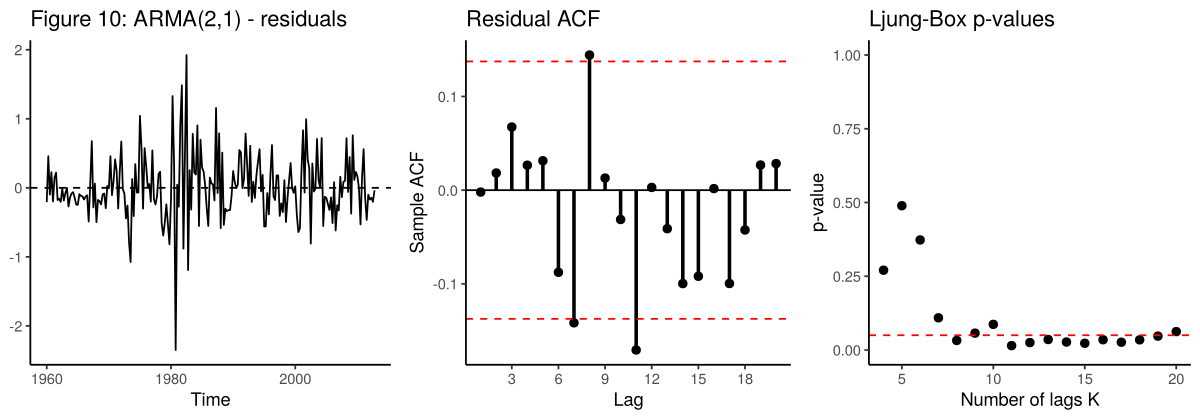

In [10]:
fits[["ARMA(2,1)"]] <- arima(sp, order = c(2, 0, 1), method = "ML")
report(fits[["ARMA(2,1)"]], "ARMA(2,1)")
options(repr.plot.height = 3.5)
resid_panel(fits[["ARMA(2,1)"]], title = "Figure 10: ARMA(2,1)")
options(repr.plot.height = 6)

**Reading the output.**

- All coefficients are significant, the AR roots are outside the unit circle (stationary) and $|\hat\beta_1|<1$ (invertible).
- The AIC and BIC are both lower than those of the AR(6) and AR(7).
- The residual ACF is much cleaner at short lags, but there are spikes at lags 7, 8 and 11, and the corrected Ljung–Box $p$-values are around or just below 5% from $K=8$ onwards.

The ARMA(2,1) is a clear improvement on the ARMA(1,1). To account for the remaining correlation at lag 7, add an MA term at lag 7.

## Model 7: ARMA(2,(1,7))

== ARMA(2,(1,7)) ==
           ar1   ar2   ma1    ma7 intercept
estimate 0.338 0.401 0.785 -0.139     1.193
s.e.     0.123 0.116 0.091  0.040     0.194
z        2.747 3.453 8.598 -3.513     6.165
p-value  0.006 0.001 0.000  0.000     0.000
Moduli of inverse AR roots: 0.824 0.486 
Moduli of inverse MA roots: 0.893 0.893 0.738 0.738 0.689 0.689 0.676 
log-likelihood -135.38 | AIC 282.76 | BIC 302.90 | sigma2 0.2080


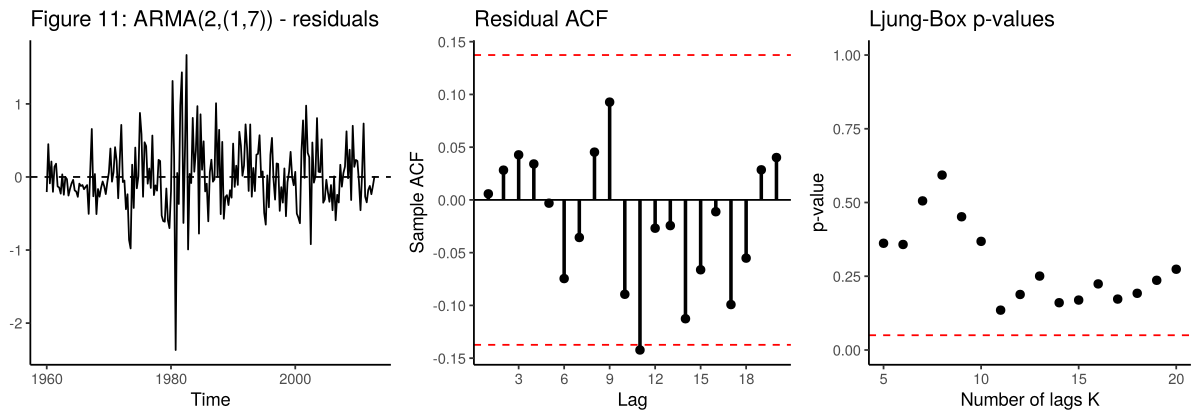

In [11]:
fits[["ARMA(2,(1,7))"]] <- arima(sp, order = c(2, 0, 7), fixed = c(NA, NA, NA, 0, 0, 0, 0, 0, NA, NA),
                                 transform.pars = FALSE, method = "ML")
report(fits[["ARMA(2,(1,7))"]], "ARMA(2,(1,7))")
options(repr.plot.height = 3.5)
resid_panel(fits[["ARMA(2,(1,7))"]], title = "Figure 11: ARMA(2,(1,7))")
options(repr.plot.height = 6)

**Reading the output.**

- All coefficients are highly significant, including $\hat\beta_7\approx-0.14$. The model is stationary and invertible.
- The residual autocorrelations at lags 7 and 8 are gone. Only lag 11 touches the band ($-0.14$) — an isolated spike at a lag with no obvious interpretation — and every Ljung–Box $p$-value is above 0.13.
- It has the lowest AIC and the lowest BIC of the seven models.

The table below summarizes the classical evidence.

In [12]:
# Summary of the seven ML fits: parameters, fit, information criteria and Ljung-Box p-values
summ_ml <- t(sapply(fits, function(f) c(n_par = sum(f$mask) + 1, loglik = f$loglik,
                                        AIC = AIC(f), BIC = BIC(f), sigma2 = f$sigma2)))
cbind(round(summ_ml, 3), lb_table(fits))

,n_par,loglik,AIC,BIC,sigma2,p(Q8),p(Q12),p(Q16),p(Q20)
AR(7),9,-135.661,289.321,319.531,0.209,0.020,0.022,0.082,0.117
AR(6),8,-137.572,291.144,317.997,0.213,0.005,0.012,0.045,0.089
AR(2),4,-145.010,298.020,311.446,0.228,0.001,0.001,0.002,0.005
"AR(1,2,7)",5,-144.680,299.360,316.143,0.228,0.000,0.001,0.002,0.004
"ARMA(1,1)",4,-142.748,293.497,306.923,0.224,0.005,0.007,0.011,0.023
"ARMA(2,1)",5,-140.101,290.201,306.984,0.218,0.032,0.025,0.035,0.062
"ARMA(2,(1,7))",6,-135.380,282.760,302.899,0.208,0.593,0.188,0.224,0.274


**Reading the table.** (`n_par` counts the ARMA coefficients, $\mu$ and $\sigma^2$, the convention of R's `AIC()` and `BIC()`.) Only the ARMA(2,(1,7)) passes the Ljung–Box test at every $K$, and it also has the lowest AIC and BIC. The AR(7) and ARMA(2,1) are the closest competitors on diagnostics; the AR(2), AR(1,2,7) and ARMA(1,1) fail.

This is where the classical analysis in Enders stops. Three questions remain that the $p$-values and information criteria above answer only indirectly:

1. How *certain* are we about each coefficient — for example, how probable is it that $\phi_7>0$ or $\beta_7<0$?
2. Can we avoid the all-or-nothing choice of dropping a lag (AR(7) vs AR(6) vs AR(1,2,7))?
3. How much does parameter uncertainty matter for quantities we care about, such as impulse responses and forecasts?

Bayesian estimation answers all three directly.

# 3&nbsp;&nbsp;Bayesian estimation

## 3.1 From likelihood to posterior

Recall from Lectures 9–11, Section 4:

$$
p(\boldsymbol\theta\mid\mathbf y)\;\propto\;L(\boldsymbol\theta)\times p(\boldsymbol\theta),
$$

posterior $\propto$ likelihood $\times$ prior. We use the **conditional** Gaussian likelihood: condition on the first $p$ observations and set pre-sample shocks to zero. With $T=212$ the first few observations carry little information, so this costs almost nothing.

**Priors for the spread.** Priors should be set on the scale of the data and stated explicitly.

| Parameter | Prior | Reasoning |
|---|---|---|
| mean $\mu$ (or constant $c$) | $N(0,10^2)$ | vague: any plausible spread level is allowed |
| AR coefficients $\phi_i$ | $N(0,1)$, truncated to the **stationary** region | weakly informative; rules out explosive dynamics |
| MA coefficients $\beta_j$ | $N(0,1)$, truncated to the **invertible** region | identifies the model (Lectures 6–8) |
| innovation variance $\sigma^2$ | $IG(a_0=2,\;d_0=0.25)$ | prior mean $d_0/(a_0-1)=0.25$, i.e. a typical quarterly shock of half a percentage point; infinite prior variance, worth about four observations |

With 200-odd observations these priors are dominated by the data, so posterior means should be close to the ML estimates (the Bernstein–von Mises theorem). The value of the Bayesian approach here lies elsewhere: exact finite-sample statements, posteriors for functions of the parameters, and a principled alternative to dropping lags.

## 3.2 Autoregressions: the Gibbs sampler

For an AR($p$), the conditional likelihood is that of the linear regression $y_t=c+\phi_1y_{t-1}+\cdots+\phi_py_{t-p}+\varepsilon_t$. With a normal prior on $\mathbf b=(c,\phi_1,\dots,\phi_p)'$ and an inverse-gamma prior on $\sigma^2$, both full conditionals are standard:

$$
\mathbf b\mid\sigma^2,\mathbf y\sim N\big(\bar{\mathbf b},\bar V\big)\ \text{truncated to stationarity},
\qquad
\sigma^2\mid\mathbf b,\mathbf y\sim IG\Big(a_0+\tfrac n2,\;d_0+\tfrac12\textstyle\sum_t\varepsilon_t^2\Big),
$$

with $\bar V=(V_0^{-1}+\sigma^{-2}X'X)^{-1}$ and $\bar{\mathbf b}=\bar V(V_0^{-1}\mathbf b_0+\sigma^{-2}X'\mathbf y)$. The **Gibbs sampler** alternates between the two draws; the truncation is imposed by redrawing $\mathbf b$ until it is stationary. The function below is `gibbs_ar()` from Lectures 9–11, unchanged except that the default $d_0$ is set on the scale of the spread.

### Predict before you simulate

With $T=212$ and the weak priors above, how close will the posterior means of $\phi_1,\dots,\phi_7$ be to the ML estimates? Will the posterior standard deviations be larger or smaller than the ML standard errors?

,mean,sd,q2.5,q97.5,ML,ML.se
phi1,1.101,0.070,0.967,1.241,1.106,0.068
phi2,-0.434,0.102,-0.639,-0.236,-0.444,0.100
phi3,0.381,0.107,0.178,0.599,0.389,0.104
phi4,-0.280,0.108,-0.490,-0.066,-0.290,0.105
phi5,0.205,0.106,-0.005,0.415,0.216,0.103
phi6,-0.288,0.102,-0.491,-0.087,-0.293,0.099
phi7,0.131,0.070,-0.005,0.269,0.133,0.068
mu,1.197,0.209,0.782,1.606,1.197,0.169
sigma2,0.223,0.023,0.182,0.271,0.209,NA


Non-stationary draws rejected: 0 


Posterior probabilities: P(phi7 > 0 | y) = 0.970   P(phi5 > 0 | y) = 0.973


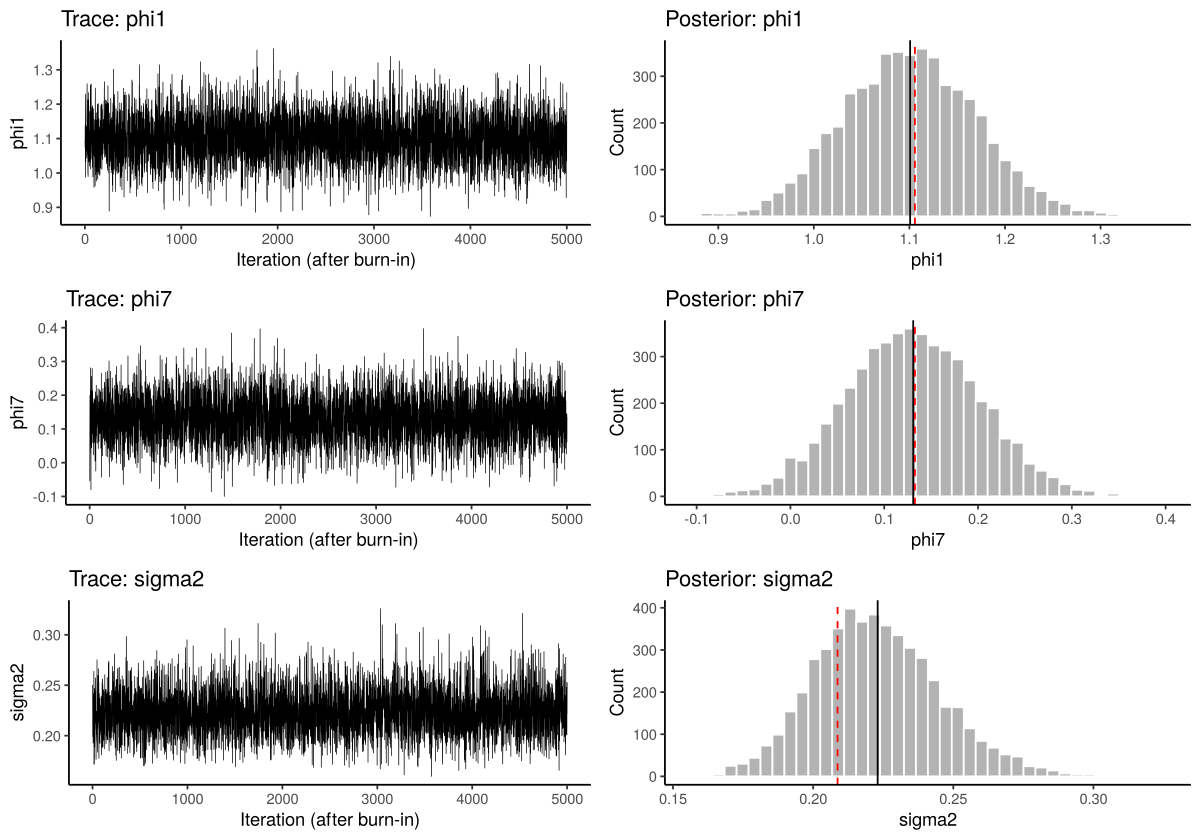

In [13]:
# Gibbs sampler for a Bayesian AR(p) (Lectures 9-11, Section 4): Normal prior on (c, phi),
# Inverse-Gamma prior on sigma2, optional truncation to the stationary region.
gibbs_ar <- function(y, p, S = 6000, burn = 1000,
                     b0 = rep(0, p + 1), V0 = diag(c(100, rep(1, p))),
                     a0 = 2, d0 = 0.25, stationary = TRUE) {
  y   <- as.numeric(y); T <- length(y)
  Y   <- y[(p + 1):T]
  X   <- cbind(1, sapply(1:p, function(i) y[(p + 1 - i):(T - i)]))   # (1, y_{t-1}, ..., y_{t-p})
  n   <- length(Y); k <- ncol(X)
  V0i <- solve(V0); XtX <- crossprod(X); XtY <- crossprod(X, Y)
  s2  <- sum(lm.fit(X, Y)$residuals^2) / (n - k)                      # start at OLS
  draws <- matrix(NA, S, k + 1, dimnames = list(NULL, c("c", paste0("phi", 1:p), "sigma2")))
  n_rej <- 0
  for (s in 1:S) {
    # 1. b | sigma2, y ~ N(b_bar, V_bar), redrawn until stationary
    V_bar <- solve(V0i + XtX / s2)
    b_bar <- V_bar %*% (V0i %*% b0 + XtY / s2)
    C     <- t(chol(V_bar))
    for (tries in 1:1000) {
      b <- as.vector(b_bar + C %*% rnorm(k))
      if (!stationary || all(Mod(polyroot(c(1, -b[-1]))) > 1)) break
      n_rej <- n_rej + 1
    }
    # 2. sigma2 | b, y ~ IG(a0 + n/2, d0 + SSR/2)
    e  <- Y - X %*% b
    s2 <- 1 / rgamma(1, shape = a0 + n / 2, rate = d0 + sum(e^2) / 2)
    draws[s, ] <- c(b, s2)
  }
  out <- if (burn > 0) draws[-seq_len(burn), , drop = FALSE] else draws
  attr(out, "rejections") <- n_rej
  out
}

# Bayesian AR(7) on the spread
set.seed(1)
draws_ar7 <- gibbs_ar(sp, p = 7)
mu_ar7    <- draws_ar7[, "c"] / (1 - rowSums(draws_ar7[, paste0("phi", 1:7)]))   # mean, draw by draw

ml7 <- coef(fits[["AR(7)"]]); se7 <- sqrt(diag(fits[["AR(7)"]]$var.coef))
cmp <- cbind(round(post_summary(cbind(draws_ar7[, paste0("phi", 1:7)], mu = mu_ar7,
                                      sigma2 = draws_ar7[, "sigma2"])), 3),
             ML = round(c(ml7, fits[["AR(7)"]]$sigma2), 3), ML.se = round(c(se7, NA), 3))
cmp
cat("Non-stationary draws rejected:", attr(draws_ar7, "rejections"), "\n")
cat(sprintf("Posterior probabilities: P(phi7 > 0 | y) = %.3f   P(phi5 > 0 | y) = %.3f\n",
            mean(draws_ar7[, "phi7"] > 0), mean(draws_ar7[, "phi5"] > 0)))

options(repr.plot.height = 7)
do.call(grid.arrange, c(mcmc_plot(draws_ar7[, "phi1"], "phi1", ml7["ar1"]),
                        mcmc_plot(draws_ar7[, "phi7"], "phi7", ml7["ar7"]),
                        mcmc_plot(draws_ar7[, "sigma2"], "sigma2", fits[["AR(7)"]]$sigma2), ncol = 2))
options(repr.plot.height = 6)

**Reading the output.**

- Posterior means are within a small fraction of a standard deviation of the ML estimates (dashed red lines), and posterior standard deviations are close to the ML standard errors. With $T=212$ and weak priors the data dominate.
- The posterior mean of $\sigma^2$ is a little larger than the ML estimate: the posterior averages over uncertainty in $\mathbf b$ and the conditional likelihood loses seven observations.
- No draw had to be rejected for non-stationarity: the data place essentially all posterior mass inside the stationary region.
- The trace plots look like stationary noise around a stable level — the Gibbs sampler mixes very well here, because each draw of $\mathbf b$ is an exact draw from its conditional.

**Posterior probabilities instead of $p$-values.** The posterior gives the direct statement students often (wrongly) read into a $p$-value: given the data and the prior, the probability that $\phi_7$ is positive is about 0.97. A two-sided $p$-value of 0.05 is *not* the probability that $\phi_7=0$; under a flat prior and a normal likelihood, $P(\phi_7>0\mid\mathbf y)\approx1-p/2$, which is why the two numbers are related here.

## 3.3 Prior sensitivity: shrinking long lags instead of dropping them

The classical approach forced a binary choice: keep $\phi_7$ (AR(7)), drop it (AR(6)), or drop lags 3–6 (AR(1,2,7)). Each choice is a **dogmatic prior** — a prior with zero variance at zero for the dropped lags and an essentially flat prior for the rest. A Bayesian can instead **shrink** coefficients on long lags towards zero, more strongly the longer the lag. A simple version of the *Minnesota prior* used for VARs later in the course sets

$$
\phi_\ell\sim N\!\Big(0,\;\frac{\lambda^2}{\ell^2}\Big),\qquad \ell=1,\dots,7 .
$$

The hyperparameter $\lambda$ controls overall tightness: $\lambda\to\infty$ gives back the unrestricted AR(7), and $\lambda\to0$ shrinks every coefficient to zero.

### Predict before you simulate

We estimate the AR(7) with $\lambda=1$, $0.5$ and $0.2$. Which coefficients will move most as $\lambda$ falls? What will happen to $\phi_1$ when $\lambda=0.2$, and to $\sigma^2$?

        lambda = 1 lambda = 0.5 lambda = 0.2
phi1         1.075        1.026        0.898
phi2        -0.375       -0.276       -0.087
phi3         0.295        0.184        0.048
phi4        -0.179       -0.083       -0.019
phi5         0.094        0.011       -0.017
phi6        -0.171       -0.083       -0.028
phi7         0.070        0.021       -0.006
sum_phi      0.809        0.801        0.790
sigma2       0.224        0.229        0.239


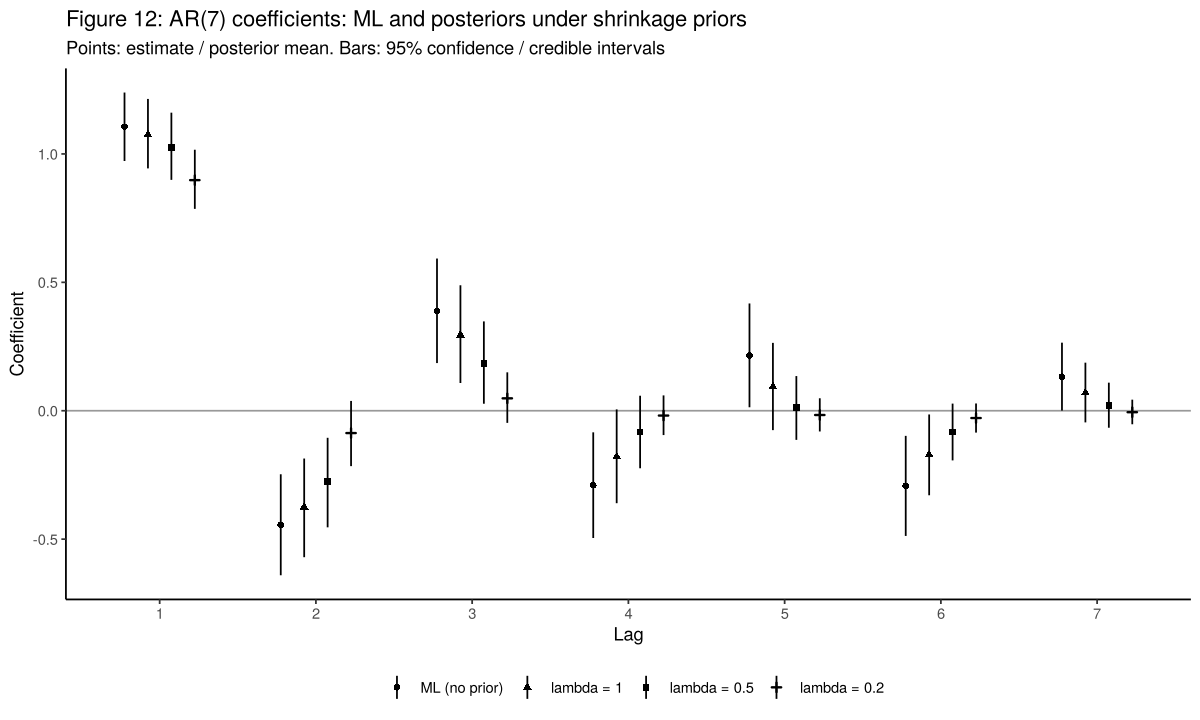

In [14]:
# AR(7) under shrinkage priors phi_l ~ N(0, lambda^2 / l^2) for three values of lambda
lambdas <- c(1, 0.5, 0.2)
shrink  <- lapply(lambdas, function(lam) {
  set.seed(1)
  gibbs_ar(sp, p = 7, V0 = diag(c(100, lam^2 / (1:7)^2)))
})
names(shrink) <- paste("lambda =", lambdas)

coef_df <- do.call(rbind, lapply(seq_along(lambdas), function(i) {
  ps <- post_summary(shrink[[i]][, paste0("phi", 1:7)])
  data.frame(lag = 1:7, mean = ps[, "mean"], lo = ps[, "q2.5"], hi = ps[, "q97.5"],
             prior = names(shrink)[i])
}))
coef_df <- rbind(coef_df, data.frame(lag = 1:7, mean = ml7[1:7], lo = ml7[1:7] - 1.96 * se7[1:7],
                                     hi = ml7[1:7] + 1.96 * se7[1:7], prior = "ML (no prior)"))
coef_df$prior <- factor(coef_df$prior, levels = c("ML (no prior)", names(shrink)))

print(round(sapply(shrink, function(d) c(colMeans(d[, paste0("phi", 1:7)]),
                                         sum_phi = mean(rowSums(d[, paste0("phi", 1:7)])),
                                         sigma2 = mean(d[, "sigma2"]))), 3))

ggplot(coef_df, aes(factor(lag), mean, shape = prior)) + theme_classic() +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_pointrange(aes(ymin = lo, ymax = hi), position = position_dodge(width = 0.6), size = 0.3) +
  labs(x = "Lag", y = "Coefficient", shape = NULL,
       title = "Figure 12: AR(7) coefficients: ML and posteriors under shrinkage priors",
       subtitle = "Points: estimate / posterior mean. Bars: 95% confidence / credible intervals") +
  theme(legend.position = "bottom")

**Reading the output.**

- With $\lambda=1$ the prior standard deviations ($1,\tfrac12,\dots,\tfrac17$) are still wide relative to the data, and the posterior is close to ML; the long lags are already pulled slightly towards zero.
- With $\lambda=0.5$ the long lags $\phi_4,\dots,\phi_7$ are shrunk to near zero and $\phi_2,\phi_3$ are pulled towards zero. The posterior looks like a **smoothed AR(3)**: the data keep the lags they need most, without any lag being deleted.
- With $\lambda=0.2$ the prior dominates: the model collapses towards an AR(1) with $\phi_1\approx0.9$, and the posterior mean of $\sigma^2$ rises because the shrunk model fits worse.
- Throughout, the **sum** $\sum_\ell\phi_\ell$ — which governs persistence and the long-run multiplier — changes much less than the individual coefficients. The data pin down persistence well, but they cannot tell us how it is distributed across lags; this is exactly why individual $t$-statistics of the AR(7) were unstable.

Which $\lambda$ is "right"? It can be chosen by the marginal likelihood or by out-of-sample forecast performance (Exercise 3). The general lesson is that **deleting a lag is an extreme prior**; shrinkage is a continuous alternative.

## 3.4 ARMA models: Metropolis-within-Gibbs

With MA terms the residuals $\varepsilon_t(\boldsymbol\theta)$ are built recursively,

$$
\varepsilon_t=y_t-\mu-\sum_{i=1}^{p}\phi_i(y_{t-i}-\mu)-\sum_{j}\beta_j\varepsilon_{t-j},
$$

so they are nonlinear in $\boldsymbol\beta$ and the full conditional of the coefficients is no longer a standard distribution. Lectures 9–11 handled an MA(1) with a single-parameter random-walk Metropolis step. Here we have up to five correlated coefficients $\boldsymbol\vartheta=(\mu,\phi_1,\phi_2,\beta_1,\beta_7)'$, so we update them **as a block**:

1. **Propose** $\boldsymbol\vartheta^\ast=\boldsymbol\vartheta^{(s-1)}+\kappa\,C\,\mathbf u$, with $\mathbf u\sim N(\mathbf 0,I)$ and $CC'=\widehat{\operatorname{Var}}(\hat{\boldsymbol\vartheta}_{ML})$. Using the ML covariance matrix gives proposals with the right *shape*: the sampler takes large steps along directions the data leave uncertain and small steps where they are informative. A standard scale is $\kappa=2.38/\sqrt k$ for $k$ parameters (Roberts, Gelman and Gilks, 1997).
2. **Accept** with probability $\alpha=\min\Big\{1,\dfrac{L(\boldsymbol\vartheta^\ast)\,p(\boldsymbol\vartheta^\ast)}{L(\boldsymbol\vartheta^{(s-1)})\,p(\boldsymbol\vartheta^{(s-1)})}\Big\}$, given the current $\sigma^2$. Proposals outside the stationary or invertible region have zero prior density and are always rejected.
3. **Draw** $\sigma^2\mid\boldsymbol\vartheta,\mathbf y\sim IG\big(a_0+\tfrac n2,\;d_0+\tfrac12\sum_t\varepsilon_t(\boldsymbol\vartheta)^2\big)$ exactly, as in the Gibbs sampler.

The function `mh_arma()` handles any ARMA with a set of MA lags, so it covers subset models such as ARMA(2,(1,7)).

In [15]:
# Residuals of an ARMA with mean mu, AR order p and MA lags ma_lags (pre-sample shocks = 0).
# theta = (mu, phi_1, ..., phi_p, beta at ma_lags). Returns e_t for t = p+1, ..., T.
arma_resid <- function(theta, y, p, ma_lags) {
  mu <- theta[1]; phi <- theta[1 + seq_len(p)]; beta <- theta[-(1:(p + 1))]
  x  <- as.numeric(y) - mu; T <- length(x)
  u  <- if (p > 0) x[(p + 1):T] - as.vector(sapply(1:p, function(i) x[(p + 1 - i):(T - i)]) %*% phi) else x
  if (length(ma_lags) == 0) return(u)
  bfull <- numeric(max(ma_lags)); bfull[ma_lags] <- beta
  as.numeric(stats::filter(u, -bfull, method = "recursive"))   # e_t = u_t - sum_j beta_j e_{t-j}
}

# Stationarity of the AR part and invertibility of the MA part.
admissible <- function(theta, p, ma_lags) {
  phi <- theta[1 + seq_len(p)]; beta <- theta[-(1:(p + 1))]
  ok_ar <- p == 0 || all(Mod(polyroot(c(1, -phi))) > 1)
  if (length(ma_lags) == 0) return(ok_ar)
  bfull <- numeric(max(ma_lags)); bfull[ma_lags] <- beta
  ok_ar && all(Mod(polyroot(c(1, bfull))) > 1)
}

# Starting values and proposal covariance from an arima() fit, reordered as (mu, phi, beta).
ml_start <- function(fit) {
  est <- coef(fit)[fit$mask]; k <- length(est); o <- c(k, 1:(k - 1))
  list(theta = est[o], Sigma = fit$var.coef[o, o])
}

# Metropolis-within-Gibbs for a Bayesian ARMA: block random-walk Metropolis for theta, Gibbs for sigma2.
# Priors: mu ~ N(m0, v_mu); each phi, beta ~ N(0, v_coef) truncated to stationarity/invertibility;
#         sigma2 ~ IG(a0, d0).
mh_arma <- function(y, p, ma_lags, start, Sigma, S = 22000, burn = 2000, scale = 2.38,
                    m0 = 0, v_mu = 100, v_coef = 1, a0 = 2, d0 = 0.25) {
  k <- length(start); theta <- as.numeric(start)
  C <- t(chol(Sigma)) * scale / sqrt(k)                  # proposal: N(0, (2.38^2 / k) * Sigma)
  n <- length(arma_resid(theta, y, p, ma_lags)); s2 <- mean(arma_resid(theta, y, p, ma_lags)^2)
  log_kernel <- function(th, s2) {                        # log likelihood + log prior, given sigma2
    if (!admissible(th, p, ma_lags)) return(-Inf)
    e <- arma_resid(th, y, p, ma_lags)
    -sum(e^2) / (2 * s2) + dnorm(th[1], m0, sqrt(v_mu), log = TRUE) +
      sum(dnorm(th[-1], 0, sqrt(v_coef), log = TRUE))
  }
  lk <- log_kernel(theta, s2); acc <- 0
  nm <- c("mu", if (p > 0) paste0("phi", 1:p), if (length(ma_lags)) paste0("beta", ma_lags), "sigma2")
  draws <- matrix(NA, S, k + 1, dimnames = list(NULL, nm))
  for (s in 1:S) {
    prop    <- theta + as.vector(C %*% rnorm(k))          # 1. propose a whole block
    lk_prop <- log_kernel(prop, s2)
    if (log(runif(1)) < lk_prop - lk) { theta <- prop; lk <- lk_prop; acc <- acc + 1 }   # 2. accept/reject
    e  <- arma_resid(theta, y, p, ma_lags)                # 3. Gibbs step for sigma2
    s2 <- 1 / rgamma(1, shape = a0 + n / 2, rate = d0 + sum(e^2) / 2)
    lk <- log_kernel(theta, s2)                           # kernel changes with sigma2
    draws[s, ] <- c(theta, s2)
  }
  out <- if (burn > 0) draws[-seq_len(burn), , drop = FALSE] else draws
  attr(out, "acceptance") <- acc / S
  out
}

### Predict before you simulate

In the ML fit of the ARMA(2,1), $\hat\phi_1\approx0.41$, $\hat\phi_2\approx0.32$ and $\hat\beta_1\approx0.70$. Many combinations of AR and MA coefficients produce similar autocorrelations. What sign do you expect for the posterior correlation between $\phi_1$ and $\beta_1$? Will the posterior of $\mu=c/(1-\phi_1-\phi_2)$ be symmetric?

Acceptance rate: 31.1%


,mean,sd,q2.5,q97.5,ML,ML.se
mu,1.212,0.234,0.753,1.667,1.191,0.199
phi1,0.482,0.132,0.242,0.765,0.413,0.122
phi2,0.274,0.123,0.011,0.495,0.319,0.114
beta1,0.638,0.115,0.355,0.806,0.698,0.091
sigma2,0.223,0.022,0.184,0.271,0.218,NA


Posterior correlations:


         mu  phi1  phi2 beta1
mu     1.00 -0.02  0.03  0.02
phi1  -0.02  1.00 -0.90 -0.87
phi2   0.03 -0.90  1.00  0.84
beta1  0.02 -0.87  0.84  1.00


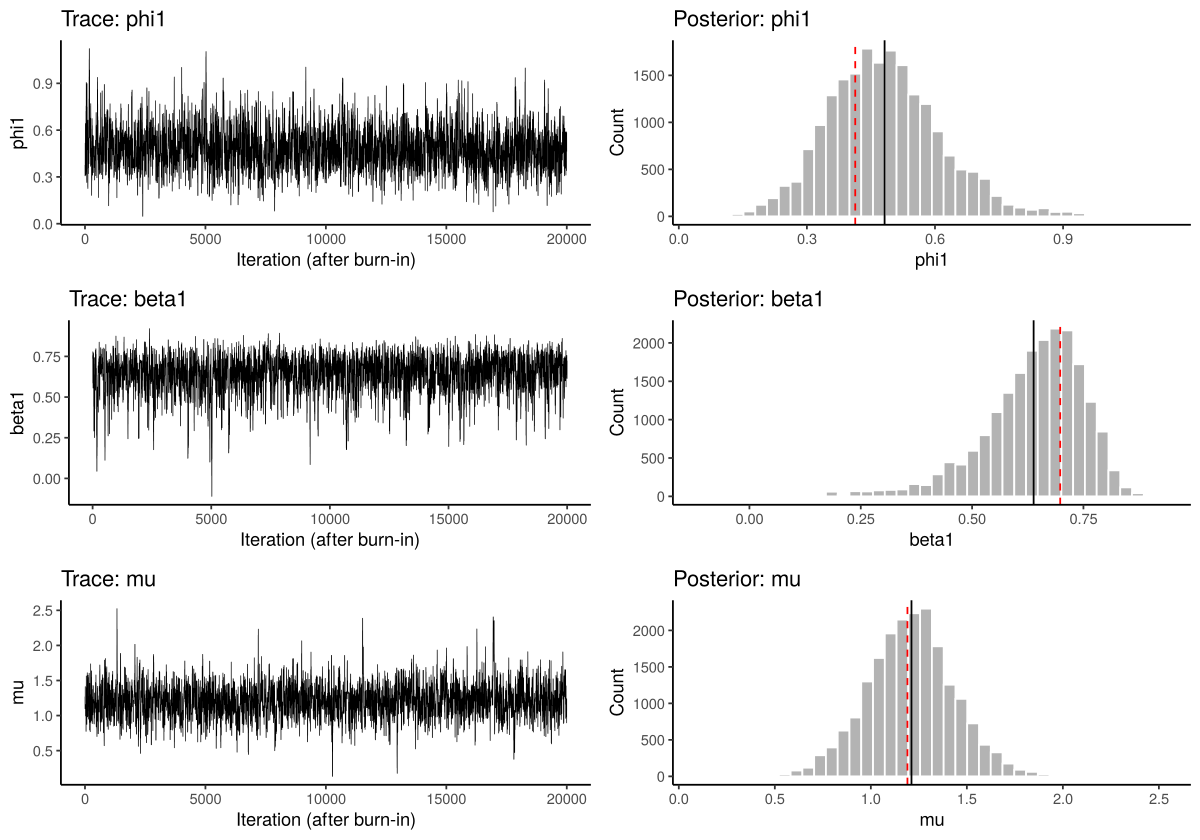

In [16]:
# Bayesian ARMA(2,1)
st21 <- ml_start(fits[["ARMA(2,1)"]])
set.seed(1)
draws_21 <- mh_arma(sp, p = 2, ma_lags = 1, start = st21$theta, Sigma = st21$Sigma)
cat(sprintf("Acceptance rate: %.1f%%\n", 100 * attr(draws_21, "acceptance")))
cbind(round(post_summary(draws_21), 3),
      ML = round(c(st21$theta, fits[["ARMA(2,1)"]]$sigma2), 3),
      ML.se = round(c(sqrt(diag(st21$Sigma)), NA), 3))
cat("Posterior correlations:\n"); print(round(cor(draws_21[, 1:4]), 2))

options(repr.plot.height = 7)
do.call(grid.arrange, c(mcmc_plot(draws_21[, "phi1"],  "phi1",  st21$theta[2]),
                        mcmc_plot(draws_21[, "beta1"], "beta1", st21$theta[4]),
                        mcmc_plot(draws_21[, "mu"],    "mu",    st21$theta[1]), ncol = 2))
options(repr.plot.height = 6)

**Reading the output.**

- The acceptance rate is around 30%, inside the 20–50% range recommended in Lectures 9–11.
- $\phi_1$, $\phi_2$ and $\beta_1$ are very strongly correlated a posteriori ($|r|$ between 0.84 and 0.90): a larger $\phi_1$ can be offset by a smaller $\beta_1$ and a larger $\phi_2$ with little loss of fit. This near-ridge is the mild version of the common-factor problem of Lectures 9–11, and it is why the block proposal with the ML covariance matrix is needed — one-parameter-at-a-time updates would crawl along the ridge.
- Posterior standard deviations are **larger** than the ML standard errors, and the posteriors are skewed: $\phi_1$ to the right, $\beta_1$ to the left with a long tail towards zero. The ML standard errors come from the curvature at the peak of the likelihood, which treats the likelihood as if it were a symmetric parabola; the posterior also reflects its shape away from the peak along the ridge.
- Because of this skewness, the posterior **means** of $\phi_1$ and $\beta_1$ differ from the ML estimates (which are posterior *modes* under a flat prior) by about half a posterior standard deviation. This is not a contradiction: mean and mode coincide only for symmetric distributions. (A smaller part of the difference comes from using the conditional rather than the exact likelihood.)
- The posterior of the mean $\mu$ is roughly symmetric and somewhat wider than the ML interval.
- The traces wander more slowly than in the Gibbs sampler; Section 3.6 checks whether the chain is long enough.

Now the preferred classical model, ARMA(2,(1,7)).

Acceptance rate: 30.9%


,mean,sd,q2.5,q97.5,ML,ML.se
mu,1.226,0.240,0.749,1.703,1.193,0.194
phi1,0.441,0.132,0.203,0.721,0.338,0.123
phi2,0.327,0.121,0.072,0.544,0.401,0.116
beta1,0.694,0.116,0.431,0.878,0.785,0.091
beta7,-0.143,0.049,-0.247,-0.048,-0.139,0.040
sigma2,0.215,0.021,0.177,0.261,0.208,NA


P(beta7 < 0 | y) = 0.9984


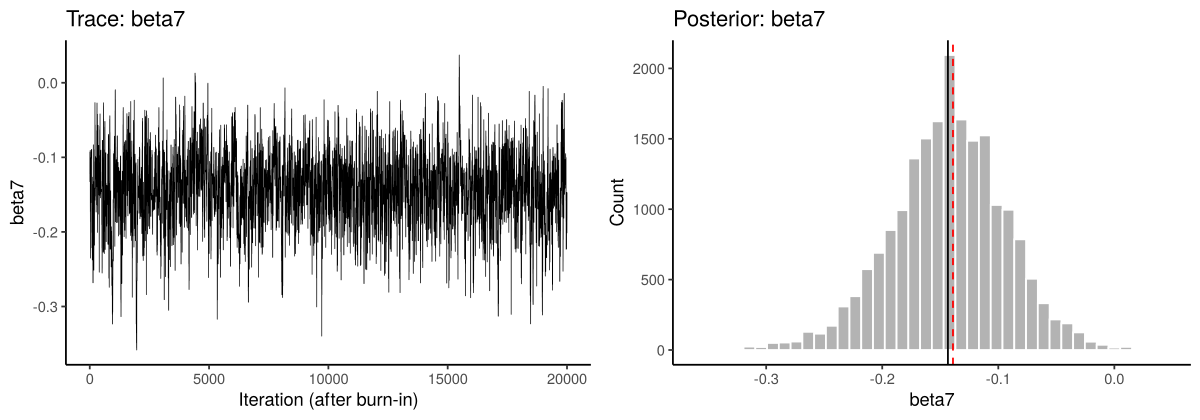

In [17]:
# Bayesian ARMA(2,(1,7))
st27 <- ml_start(fits[["ARMA(2,(1,7))"]])
set.seed(1)
draws_27 <- mh_arma(sp, p = 2, ma_lags = c(1, 7), start = st27$theta, Sigma = st27$Sigma)
cat(sprintf("Acceptance rate: %.1f%%\n", 100 * attr(draws_27, "acceptance")))
cbind(round(post_summary(draws_27), 3),
      ML = round(c(st27$theta, fits[["ARMA(2,(1,7))"]]$sigma2), 3),
      ML.se = round(c(sqrt(diag(st27$Sigma)), NA), 3))
cat(sprintf("P(beta7 < 0 | y) = %.4f\n", mean(draws_27[, "beta7"] < 0)))

options(repr.plot.height = 3.5)
do.call(grid.arrange, c(mcmc_plot(draws_27[, "beta7"], "beta7", st27$theta[5]), ncol = 2))
options(repr.plot.height = 6)

**Reading the output.** Posterior means are again close to the ML estimates, with somewhat wider and skewed posteriors for the correlated $(\phi_1,\phi_2,\beta_1)$ block. The lag-7 MA coefficient is the most precisely determined: its posterior is nearly symmetric, centred near $-0.14$, and puts about 99.8% of its mass below zero.

Whether $\beta_7$ is *economically* plausible is a separate question (Section 6) — a posterior probability, like a $p$-value, measures the strength of the evidence in this sample, not whether a feature reflects the true data-generating process.

## 3.5 A Bayesian residual check

Diagnostic checking carries over to the Bayesian setting. Instead of one residual series we have one for every posterior draw, so each residual autocorrelation has a posterior distribution. If the model is adequate, these distributions should be centred inside the $\pm2/\sqrt T$ bands.

**Predict:** at which lag will the ARMA(2,1) and the ARMA(2,(1,7)) differ most?

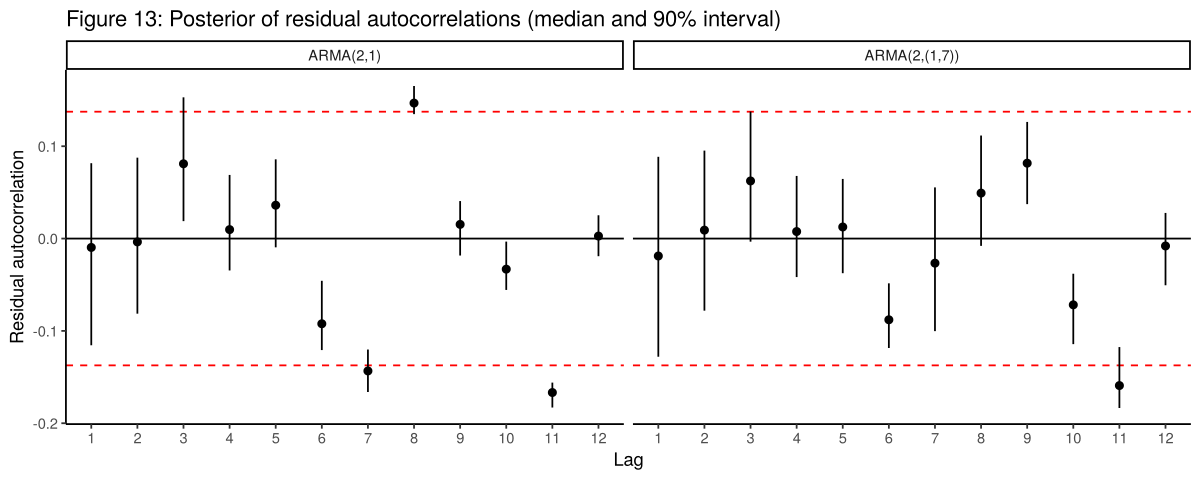

In [18]:
# Posterior distribution of residual autocorrelations, lags 1-12, from 500 draws of each model
resid_acf_post <- function(draws, p, ma_lags, L = 12, n_draws = 500) {
  k    <- 1 + p + length(ma_lags)
  keep <- round(seq(1, nrow(draws), length.out = n_draws))
  r    <- sapply(keep, function(s) acf(arma_resid(draws[s, 1:k], sp, p, ma_lags),
                                       plot = FALSE, lag.max = L)$acf[-1])
  data.frame(lag = 1:L, med = apply(r, 1, median),
             lo = apply(r, 1, quantile, 0.05), hi = apply(r, 1, quantile, 0.95))
}
racf <- rbind(cbind(resid_acf_post(draws_21, 2, 1),       model = "ARMA(2,1)"),
              cbind(resid_acf_post(draws_27, 2, c(1, 7)), model = "ARMA(2,(1,7))"))
racf$model <- factor(racf$model, levels = c("ARMA(2,1)", "ARMA(2,(1,7))"))
b <- 2 / sqrt(T)
options(repr.plot.height = 4)
ggplot(racf, aes(lag, med)) + theme_classic() + facet_wrap(~ model) +
  geom_hline(yintercept = 0) +
  geom_hline(yintercept = c(-b, b), linetype = "dashed", colour = "red") +
  geom_pointrange(aes(ymin = lo, ymax = hi), size = 0.3) +
  scale_x_continuous(breaks = 1:12) +
  labs(x = "Lag", y = "Residual autocorrelation",
       title = "Figure 13: Posterior of residual autocorrelations (median and 90% interval)")
options(repr.plot.height = 6)

**Reading the graph.**

- For the ARMA(2,1) the posterior intervals at lag 7 (straddling the lower band) and lag 8 (entirely above the upper band) are narrow: **across all plausible parameter values** the model leaves correlation at lags 7–8. This is not an artefact of one particular estimate.
- Adding $\beta_7$ removes both problems: in the ARMA(2,(1,7)) the lag-7 and lag-8 intervals are well inside the bands.
- Both models leave a negative autocorrelation at lag 11 that sits at or just beyond the band. It is isolated, at a lag with no obvious economic interpretation, and the pooled Ljung–Box test does not reject for the ARMA(2,(1,7)); following the cautions of Section 1, we do not chase it.
- Intervals at lags 1–3 are wide: short-lag residual autocorrelations depend most on the uncertain $(\phi_1,\phi_2,\beta_1)$ block. Classical residual plots, computed at the single ML estimate, cannot show this.

## 3.6 Is the sampler working? MCMC diagnostics

An MCMC chain is itself a stationary time series, so the tools of this course apply to it.

- **Effective sample size.** With chain autocorrelations $\rho_k$, $\text{ESS}=S/(1+2\sum_{k\ge1}\rho_k)$: the number of independent draws that would give the same precision for a posterior mean.
- **Multiple chains.** Run $m$ chains from dispersed starting values. If they have converged, the variance *between* chain means $B/n$ should be small relative to the average variance *within* chains $W$. The Gelman–Rubin statistic
$$
\hat R=\sqrt{\frac{\tfrac{n-1}{n}W+\tfrac{B}{n}}{W}}
$$
should be close to 1 (a common rule is $\hat R<1.01$–$1.05$).

**Predict:** which sampler will have the larger ESS for $\phi_1$ — the Gibbs sampler of the AR(7) or the Metropolis sampler of the ARMA(2,1)? Why?

Effective sample sizes (draws kept after burn-in in brackets):


$`AR(7), Gibbs [5000]`
     c   phi1   phi2   phi3   phi4   phi5   phi6   phi7 sigma2 
  4929   4901   4798   4700   4908   5000   5000   4985   4581 

$`ARMA(2,1), Metropolis [20000]`
    mu   phi1   phi2  beta1 sigma2 
  1104   1216   1205    988  15699 

$`ARMA(2,(1,7)), Metropolis [20000]`
    mu   phi1   phi2  beta1  beta7 sigma2 
   844   1063   1071    811    685  13691 




R-hat after discarding the first 2000 draws of each chain:


    mu   phi1   phi2  beta1 sigma2 
 1.000  1.001  1.001  1.000  1.000 


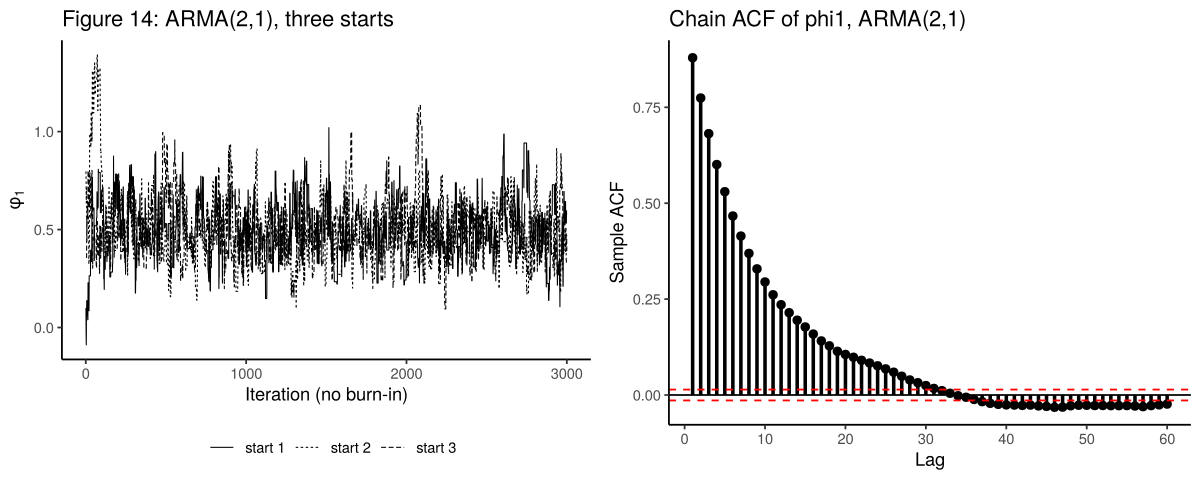

In [19]:
# Effective sample size (sum of autocorrelations truncated at the first negative one)
ess <- function(z) {
  r <- acf(z, plot = FALSE, lag.max = 1000)$acf[-1]
  k <- which(r < 0)[1]; if (is.na(k)) k <- length(r) + 1
  length(z) / (1 + 2 * sum(r[seq_len(k - 1)]))
}
cat("Effective sample sizes (draws kept after burn-in in brackets):\n")
print(list("AR(7), Gibbs [5000]"               = round(apply(draws_ar7, 2, ess)),
           "ARMA(2,1), Metropolis [20000]"     = round(apply(draws_21, 2, ess)),
           "ARMA(2,(1,7)), Metropolis [20000]" = round(apply(draws_27, 2, ess))))

# Gelman-Rubin R-hat: three ARMA(2,1) chains from dispersed (admissible) starting values
rhat <- function(chains) {
  n <- length(chains[[1]])
  W <- mean(sapply(chains, var)); B <- n * var(sapply(chains, mean))
  sqrt(((n - 1) / n * W + B / n) / W)
}
starts <- list(c(0.0, 0.10,  0.10,  0.10),
               c(2.5, 0.90, -0.20, -0.50),
               c(0.5, 0.20,  0.50,  0.90))
set.seed(2)
chains <- lapply(starts, function(s0) mh_arma(sp, 2, 1, s0, st21$Sigma, S = 12000, burn = 0))
cat("\nR-hat after discarding the first 2000 draws of each chain:\n")
print(round(sapply(colnames(chains[[1]]), function(v)
  rhat(lapply(chains, function(ch) ch[-(1:2000), v]))), 3))

tr <- do.call(rbind, lapply(1:3, function(i)
  data.frame(iter = 1:3000, phi1 = chains[[i]][1:3000, "phi1"], chain = paste("start", i))))
options(repr.plot.height = 4)
grid.arrange(
  ggplot(tr, aes(iter, phi1, linetype = chain)) + theme_classic() + geom_line(linewidth = 0.3) +
    labs(x = "Iteration (no burn-in)", y = expression(phi[1]), linetype = NULL,
         title = "Figure 14: ARMA(2,1), three starts") +
    theme(legend.position = "bottom"),
  sample_acf_plot(draws_21[, "phi1"], L = 60, by = 10, title = "Chain ACF of phi1, ARMA(2,1)"),
  ncol = 2)
options(repr.plot.height = 6)

**Reading the output.**

- The Gibbs sampler for the AR(7) produces almost independent draws: ESS is close to the number of draws.
- The Metropolis chains are much more autocorrelated — each step is a small random-walk move, and about 70% of proposals are rejected — so 20,000 draws are worth only about 700–1,200 independent ones for the coefficients (the exact Gibbs step for $\sigma^2$ does far better). The chain ACF of $\phi_1$ decays slowly and dies out only after about 35 lags, just like the correlogram of a persistent AR process. About a thousand effective draws are ample for posterior means and central intervals; for extreme tail quantiles, run longer chains.
- The three chains started far apart reach the same region within about a hundred iterations, and $\hat R$ is 1.00 for every parameter.

In applied work these samplers are rarely hand-written: `rstan`/`brms` (Hamiltonian Monte Carlo) and `bayesforecast` fit Bayesian ARMA models directly, and `coda` computes ESS and $\hat R$. Writing the sampler once is the best way to understand what they do.

## 3.7 Posteriors of functions of parameters: impulse responses

The impulse response of the spread to a unit innovation is given by the Wold weights $\psi_j$ (Lectures 6–8), which are nonlinear functions of $(\phi_1,\phi_2,\beta_1,\beta_7)$. Classical inference would need the delta method or a bootstrap. The Bayesian answer is to compute $\psi_0,\dots,\psi_{20}$ **draw by draw** with `ARMAtoMA()` and summarize.

  h    ml   med  lo68  hi68  lo95  hi95
  0 1.000 1.000 1.000 1.000 1.000 1.000
  1 1.123 1.134 1.068 1.203 1.002 1.273
  2 0.780 0.826 0.746 0.919 0.670 1.020
  3 0.714 0.733 0.640 0.845 0.555 0.973
  4 0.554 0.585 0.482 0.718 0.393 0.876
  8 0.214 0.223 0.123 0.355 0.038 0.576
 12 0.089 0.098 0.040 0.199 0.009 0.408
 16 0.040 0.047 0.015 0.117 0.003 0.298
 20 0.019 0.022 0.006 0.069 0.001 0.222



Largest inverse AR root: posterior median 0.831, 95% interval [0.738, 0.925]


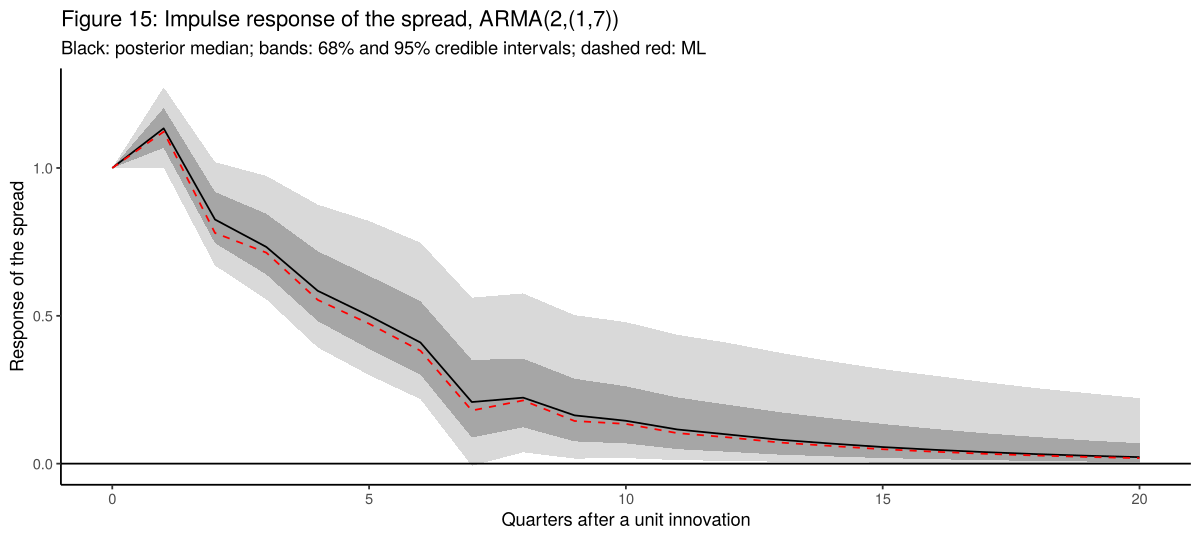

In [20]:
# Posterior of the impulse response of the ARMA(2,(1,7)), horizons 0-20
H_irf <- 20
keep  <- seq(1, nrow(draws_27), by = 10)
irf_draws <- t(sapply(keep, function(s) {
  ma <- c(draws_27[s, "beta1"], 0, 0, 0, 0, 0, draws_27[s, "beta7"])
  c(1, ARMAtoMA(ar = draws_27[s, c("phi1", "phi2")], ma = ma, lag.max = H_irf))
}))
cf27   <- coef(fits[["ARMA(2,(1,7))"]])
irf_ml <- c(1, ARMAtoMA(ar = cf27[1:2], ma = cf27[3:9], lag.max = H_irf))
irf_df <- data.frame(h = 0:H_irf, ml = irf_ml, med = apply(irf_draws, 2, median),
                     lo68 = apply(irf_draws, 2, quantile, 0.16), hi68 = apply(irf_draws, 2, quantile, 0.84),
                     lo95 = apply(irf_draws, 2, quantile, 0.025), hi95 = apply(irf_draws, 2, quantile, 0.975))
print(round(irf_df[c(1:5, 9, 13, 17, 21), ], 3), row.names = FALSE)

# Persistence: the largest modulus of the inverse AR roots
pers <- apply(draws_27[keep, c("phi1", "phi2")], 1, function(ph) max(Mod(1 / polyroot(c(1, -ph)))))
cat(sprintf("\nLargest inverse AR root: posterior median %.3f, 95%% interval [%.3f, %.3f]\n",
            median(pers), quantile(pers, 0.025), quantile(pers, 0.975)))

options(repr.plot.height = 4.5)
ggplot(irf_df, aes(h)) + theme_classic() +
  geom_ribbon(aes(ymin = lo95, ymax = hi95), fill = "grey85") +
  geom_ribbon(aes(ymin = lo68, ymax = hi68), fill = "grey65") +
  geom_line(aes(y = med)) +
  geom_line(aes(y = ml), linetype = "dashed", colour = "red") +
  geom_hline(yintercept = 0) +
  labs(x = "Quarters after a unit innovation", y = "Response of the spread",
       title = "Figure 15: Impulse response of the spread, ARMA(2,(1,7))",
       subtitle = "Black: posterior median; bands: 68% and 95% credible intervals; dashed red: ML")
options(repr.plot.height = 6)

**Reading the output.** A unit shock to the spread is amplified in the following quarter ($\psi_1=\phi_1+\beta_1>1$) and then dies out over roughly three years. The sharp drop at horizon 7 is the negative $\beta_7$ at work: seven quarters after the shock, part of its effect is reversed. The credible bands are asymmetric — wider on the upper side at medium horizons — because draws with persistence close to one generate long-lived responses; the delta method would impose symmetry. The ML impulse response (dashed red) lies close to the posterior median.

# 4&nbsp;&nbsp;Comparing the candidates

Information criteria penalize the maximized log-likelihood for the number of parameters $n$:

$$
\text{AIC}=-2\ell(\hat{\boldsymbol\theta})+2n,
\qquad
\text{BIC}=-2\ell(\hat{\boldsymbol\theta})+n\ln T .
$$

BIC has a **Bayesian interpretation** (Lectures 9–11, Section 5): $-\text{BIC}_k/2$ approximates the log marginal likelihood $\ln p(\mathbf y\mid M_k)$, so with equal prior probabilities for the models

$$
P(M_k\mid\mathbf y)\;\approx\;\frac{\exp(-\text{BIC}_k/2)}{\sum_j\exp(-\text{BIC}_j/2)} .
$$

In [21]:
# AIC, BIC and approximate posterior model probabilities from BIC (equal prior odds)
ic <- data.frame(model = names(fits), n_par = summ_ml[, "n_par"],
                 AIC = summ_ml[, "AIC"], BIC = summ_ml[, "BIC"], row.names = NULL)
ic$dAIC      <- ic$AIC - min(ic$AIC)
ic$dBIC      <- ic$BIC - min(ic$BIC)
ic$post_prob <- exp(-ic$dBIC / 2) / sum(exp(-ic$dBIC / 2))
ic$LB_passes <- apply(lb_table(fits), 1, function(p) all(p > 0.05))
print(cbind(ic[, 1:2], round(ic[, 3:7], 3), LB_passes = ic$LB_passes), row.names = FALSE)

         model n_par     AIC     BIC   dAIC   dBIC post_prob LB_passes
         AR(7)     9 289.321 319.531  6.562 16.631     0.000     FALSE
         AR(6)     8 291.144 317.997  8.384 15.098     0.000     FALSE
         AR(2)     4 298.020 311.446 15.260  8.547     0.011     FALSE
     AR(1,2,7)     5 299.360 316.143 16.601 13.244     0.001     FALSE
     ARMA(1,1)     4 293.497 306.923 10.737  4.024     0.105     FALSE
     ARMA(2,1)     5 290.201 306.984  7.442  4.085     0.101     FALSE
 ARMA(2,(1,7))     6 282.760 302.899  0.000  0.000     0.782      TRUE


**Reading the table.**

- Both AIC and BIC select the ARMA(2,(1,7)), and BIC gives it an approximate posterior probability of about 0.8.
- The ARMA(1,1) and ARMA(2,1) share most of the remaining probability. Note that the ARMA(1,1) receives about 10% **although it fails the residual checks**: information criteria (and posterior model probabilities) only compare the models on the list. They complement diagnostics; they never replace them.
- The long autoregressions receive almost no posterior probability: they fit about as well as the ARMA(2,(1,7)) but need three or four more parameters, and BIC's $\ln T\approx5.4$ penalty per parameter is heavy.

Rather than choosing one model, the probabilities can also be used as weights to **average** forecasts across models (Bayesian model averaging; Exercise 5).

# 5&nbsp;&nbsp;Forecasting

## 5.1 Out-of-sample evaluation: classical vs Bayesian

We mimic real time with a **fixed scheme**: estimate on 1960Q1–2000Q2 ($R=162$), then produce one-step-ahead forecasts for 2000Q3–2012Q4 ($H=50$) with the parameters held fixed. We compare the AR(7) and the ARMA(2,(1,7)), each estimated by ML and by Bayesian methods.

- The **ML** forecast plugs in $\hat{\boldsymbol\theta}$: $\hat y_{t+1|t}=\hat\mu+\sum_i\hat\phi_i(y_{t+1-i}-\hat\mu)+\sum_j\hat\beta_j\hat\varepsilon_{t+1-j}$.
- The **Bayesian** point forecast is the mean of the posterior predictive distribution, $E(y_{t+1}\mid\mathbf y_{1:t})=\int\hat y_{t+1|t}(\boldsymbol\theta)\,p(\boldsymbol\theta\mid\mathbf y_{1:R})\,d\boldsymbol\theta$: the one-step forecast is computed for each posterior draw and then averaged.

The one-step forecast is $y_t-\varepsilon_t$, where $\varepsilon_t$ comes from the residual recursion run through the whole sample with fixed parameters.

**Predict:** with $R=162$, how different will the ML and Bayesian forecasts be? Which model will have the lower RMSE?

In [22]:
# Fixed-scheme one-step forecasts for 2000Q3-2012Q4 from models estimated on 1960Q1-2000Q2
sp_tr <- window(sp, end = c(2000, 2)); sp_te <- window(sp, start = c(2000, 3))
R <- length(sp_tr); H <- length(sp_te); act <- as.numeric(sp_te)

onestep <- function(theta, p, ma_lags) {        # one-step forecasts y_t - e_t over the test sample
  e <- arma_resid(theta, sp, p, ma_lags)
  tail(as.numeric(sp)[(p + 1):T] - e, H)
}

# ML on the estimation sample
m_ar7  <- arima(sp_tr, order = c(7, 0, 0), method = "ML")
m_arma <- arima(sp_tr, order = c(2, 0, 7), fixed = c(NA, NA, NA, 0, 0, 0, 0, 0, NA, NA),
                transform.pars = FALSE, method = "ML")
st_ar7 <- ml_start(m_ar7); st_arma <- ml_start(m_arma)

# Bayesian posteriors on the estimation sample
set.seed(1); b_ar7 <- gibbs_ar(sp_tr, p = 7)
th_ar7 <- cbind(b_ar7[, "c"] / (1 - rowSums(b_ar7[, paste0("phi", 1:7)])), b_ar7[, paste0("phi", 1:7)])
set.seed(1); b_arma <- mh_arma(sp_tr, 2, c(1, 7), st_arma$theta, st_arma$Sigma)

fc <- cbind(
  "AR(7), ML"            = onestep(st_ar7$theta, 7, integer(0)),
  "AR(7), Bayes"         = rowMeans(sapply(seq(1, nrow(th_ar7), by = 5),  function(s) onestep(th_ar7[s, ], 7, integer(0)))),
  "ARMA(2,(1,7)), ML"    = onestep(st_arma$theta, 2, c(1, 7)),
  "ARMA(2,(1,7)), Bayes" = rowMeans(sapply(seq(1, nrow(b_arma), by = 20), function(s) onestep(b_arma[s, 1:5], 2, c(1, 7)))))
E <- act - fc

naive_mae <- mean(abs(diff(as.numeric(sp_tr))))         # MASE scale: in-sample MAE of the random walk
acc <- t(apply(E, 2, function(e) c(ME = mean(e), MAE = mean(abs(e)), RMSE = sqrt(mean(e^2)),
                                   MAPE = 100 * mean(abs(e / act)), MASE = mean(abs(e)) / naive_mae)))
round(acc, 3)
cat(sprintf("Largest |ML - Bayes| difference in forecasts: AR(7) %.3f, ARMA(2,(1,7)) %.3f\n",
            max(abs(fc[, 1] - fc[, 2])), max(abs(fc[, 3] - fc[, 4]))))
cat(sprintf("Test-sample observations with |spread| < 0.2: %d of %d\n", sum(abs(act) < 0.2), H))

,ME,MAE,RMSE,MAPE,MASE
"AR(7), ML",0.018,0.330,0.425,132.938,0.924
"AR(7), Bayes",0.019,0.329,0.424,132.362,0.922
"ARMA(2,(1,7)), ML",0.017,0.311,0.402,126.245,0.871
"ARMA(2,(1,7)), Bayes",0.013,0.308,0.402,123.351,0.862


Largest |ML - Bayes| difference in forecasts: AR(7) 0.019, ARMA(2,(1,7)) 0.085


Test-sample observations with |spread| < 0.2: 5 of 50


**Reading the output.**

- ML and Bayesian point forecasts are almost identical: with 162 observations and weak priors the posterior is concentrated near the MLE, and averaging the forecast over the posterior changes it by less than 0.1 percentage point in every quarter.
- The ARMA(2,(1,7)) has lower MAE, RMSE and MASE than the AR(7). Both have MASE below one, so both beat a naive no-change forecast.
- **Ignore the MAPE column.** The spread is close to zero (and even negative) in several test quarters, so $e_\tau/y_\tau$ explodes. MAPE above 100% here says nothing about forecast quality (Lectures 9–11, Section 8). MASE is the appropriate scale-free measure.

Is the difference between the two models significant? The two models are **not nested**, and parameters are fixed, so the Diebold–Mariano test applies. We use the Harvey–Leybourne–Newbold small-sample correction with $t(H-1)$ critical values.

Mean loss differential 0.0191 | DM = 2.25 | HLN-corrected 2.23 | p = 0.031


Correlation of the two models' forecast errors: 0.98


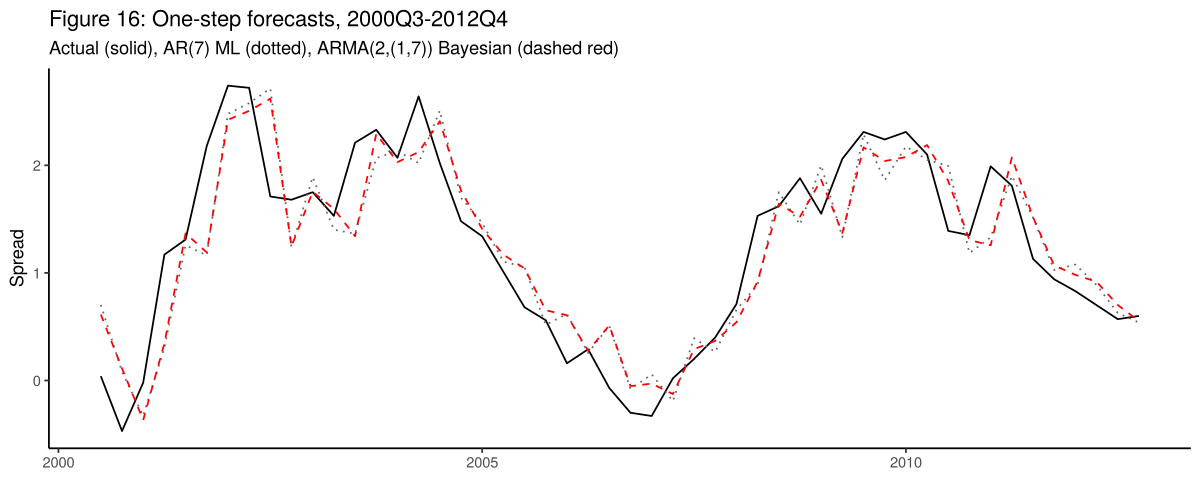

In [23]:
# Diebold-Mariano test, squared-error loss: AR(7) vs ARMA(2,(1,7)), ML forecasts, h = 1
e1 <- E[, "AR(7), ML"]; e2 <- E[, "ARMA(2,(1,7)), ML"]
d  <- e1^2 - e2^2                                          # positive: AR(7) worse
DM <- mean(d) / sqrt(mean((d - mean(d))^2) / H)
DMs <- DM * sqrt((H - 1) / H)                              # HLN correction for h = 1
cat(sprintf("Mean loss differential %.4f | DM = %.2f | HLN-corrected %.2f | p = %.3f\n",
            mean(d), DM, DMs, 2 * pt(-abs(DMs), H - 1)))
cat(sprintf("Correlation of the two models' forecast errors: %.2f\n", cor(e1, e2)))

fc_df <- data.frame(time = as.numeric(time(sp_te)), actual = act,
                    AR7 = fc[, "AR(7), ML"], ARMA = fc[, "ARMA(2,(1,7)), Bayes"])
options(repr.plot.height = 4)
ggplot(fc_df, aes(time)) + theme_classic() +
  geom_line(aes(y = actual)) +
  geom_line(aes(y = AR7), linetype = "dotted", colour = "grey40") +
  geom_line(aes(y = ARMA), linetype = "dashed", colour = "red") +
  labs(x = NULL, y = "Spread",
       title = "Figure 16: One-step forecasts, 2000Q3-2012Q4",
       subtitle = "Actual (solid), AR(7) ML (dotted), ARMA(2,(1,7)) Bayesian (dashed red)")
options(repr.plot.height = 6)

**Reading the output.** The forecast errors of the two models are highly correlated (both models make similar mistakes), which is why the simple $F$-test is inappropriate and the Diebold–Mariano test is used. The test rejects equal accuracy at the 5% level in favour of the ARMA(2,(1,7)). The out-of-sample evidence agrees with the in-sample information criteria and diagnostics. Both models lag behind the large movements of 2001 and 2008, when monetary policy cut short-term rates rapidly; no univariate model can anticipate such policy shifts.

## 5.2 The Bayesian predictive distribution

A plug-in forecast interval $\hat y_{T+h|T}\pm1.96\,\hat\sigma\big(\sum_{i<h}\hat\psi_i^2\big)^{1/2}$ treats the estimated parameters as if they were the truth. The Bayesian **predictive distribution**

$$
p(y_{T+1},\dots,y_{T+h}\mid\mathbf y)=\int p(y_{T+1},\dots,y_{T+h}\mid\boldsymbol\theta,\mathbf y)\,p(\boldsymbol\theta\mid\mathbf y)\,d\boldsymbol\theta
$$

integrates over parameter uncertainty. It is computed by simulation: for each posterior draw, rebuild the residuals and simulate one future path with fresh shocks $\varepsilon\sim N(0,\sigma^{2(s)})$. Quantiles across paths give predictive intervals.

**Predict:** using the full-sample ARMA(2,(1,7)), will the Bayesian 95% interval be noticeably wider than the plug-in interval? At which horizons?

Width of 95% forecast intervals (percentage points):


                     h=1  h=2  h=4  h=8 h=12
Plug-in (ML)        1.79 2.69 3.29 3.61 3.66
Bayesian predictive 1.83 2.72 3.54 3.88 4.12


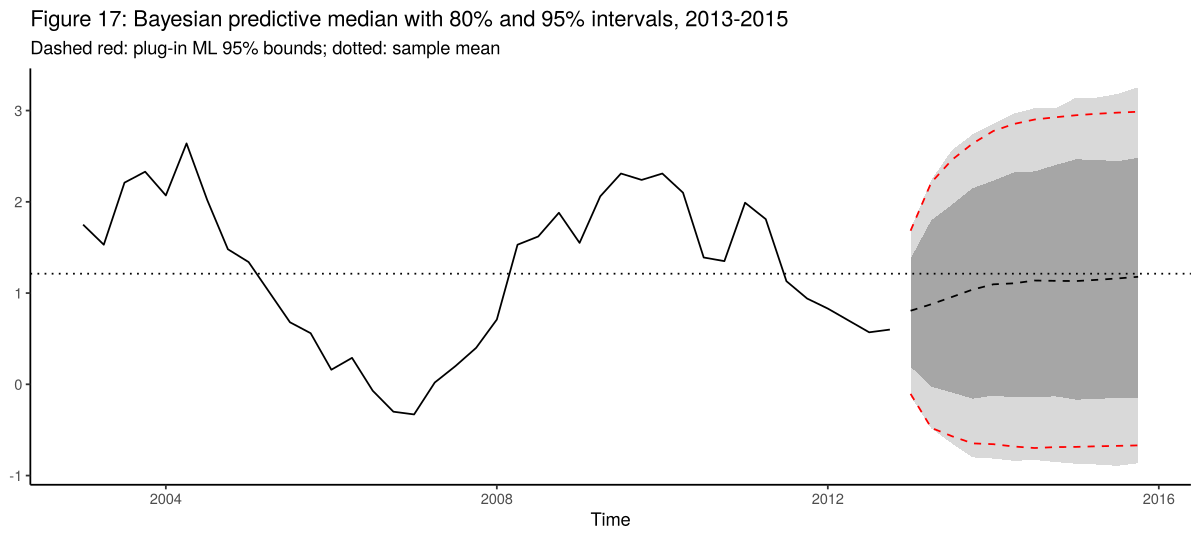

In [24]:
# Posterior predictive simulation for an ARMA with subset MA lags: one future path per posterior draw
post_pred_arma <- function(draws, y, p, ma_lags, H, thin = 5) {
  y <- as.numeric(y); keep <- seq(1, nrow(draws), by = thin)
  q <- max(c(ma_lags, 0)); k <- 1 + p + length(ma_lags)
  paths <- matrix(NA, length(keep), H)
  for (i in seq_along(keep)) {
    th <- draws[keep[i], 1:k]; sg <- sqrt(draws[keep[i], k + 1])
    mu <- th[1]; phi <- th[1 + seq_len(p)]
    bfull <- numeric(q); if (q > 0) bfull[ma_lags] <- th[-(1:(p + 1))]
    e  <- arma_resid(th, y, p, ma_lags)
    xh <- rev(tail(y - mu, max(p, 1)))           # x_T, x_{T-1}, ...  (x = y - mu)
    eh <- rev(tail(e, max(q, 1)))                # e_T, e_{T-1}, ...
    for (j in 1:H) {
      eps   <- sg * rnorm(1)
      x_new <- sum(phi * xh[seq_len(p)]) + eps + sum(bfull * eh[seq_len(q)])
      paths[i, j] <- mu + x_new
      xh <- c(x_new, xh); eh <- c(eps, eh)
    }
  }
  paths
}

Hf <- 12
set.seed(1)
paths <- post_pred_arma(draws_27, sp, 2, c(1, 7), H = Hf)
pr    <- predict(fits[["ARMA(2,(1,7))"]], n.ahead = Hf)          # plug-in ML forecasts

widths <- rbind("Plug-in (ML)"        = 2 * 1.96 * as.numeric(pr$se),
                "Bayesian predictive" = apply(paths, 2, function(z) diff(quantile(z, c(0.025, 0.975)))))
colnames(widths) <- paste0("h=", 1:Hf)
cat("Width of 95% forecast intervals (percentage points):\n"); print(round(widths[, c(1, 2, 4, 8, 12)], 2))

qs <- apply(paths, 2, quantile, probs = c(0.025, 0.1, 0.5, 0.9, 0.975))
tf <- 2012.75 + (1:Hf) / 4
options(repr.plot.height = 4.5)
fan_plot(sp, qs[3, ], qs[2, ], qs[4, ], qs[1, ], qs[5, ], n_show = 40, t_end = 2012.75, freq = 4,
         title = "Figure 17: Bayesian predictive median with 80% and 95% intervals, 2013-2015") +
  geom_line(data = data.frame(time = tf, v = as.numeric(pr$pred - 1.96 * pr$se)), aes(time, v),
            colour = "red", linetype = "dashed") +
  geom_line(data = data.frame(time = tf, v = as.numeric(pr$pred + 1.96 * pr$se)), aes(time, v),
            colour = "red", linetype = "dashed") +
  geom_hline(yintercept = mean(sp), linetype = "dotted") +
  labs(subtitle = "Dashed red: plug-in ML 95% bounds; dotted: sample mean")
options(repr.plot.height = 6)

**Reading the output.** At the end of 2012 the spread (0.6) is below its mean, so the forecasts rise gradually towards the mean of about 1.2. At $h=1$ the two intervals are almost the same width, because one-step uncertainty is dominated by the next shock. At longer horizons the predictive interval is wider: uncertainty about persistence and about the mean $\mu$ — whose posterior has a long tail — accumulates with the horizon, and the plug-in interval ignores it. With 212 observations the difference is modest; in short samples it can be large (Lectures 9–11, Section 7).

One more caveat applies to both intervals: they assume Gaussian, homoskedastic shocks, and the residual plots in Section 2 show calmer and more volatile periods. If volatility clusters, the intervals are too wide in calm periods and too narrow in turbulent ones (ARCH/GARCH models, later in the course).

# 6&nbsp;&nbsp;Discussion: what the analysis does and does not settle

Although the ARMA(2,(1,7)) passes every check here, other researchers might reasonably choose differently.

- **Parsimony versus overfitting.** Is it plausible that a shock seven quarters ago has a *direct* effect on today's spread, while lags 3 to 6 have none? The lag-7 term may capture an idiosyncrasy of this sample rather than a feature of the data-generating process. Overfitting means fitting idiosyncrasies of a particular sample that are not representative of the process that generated it; expanding a model to capture every feature of the data invites it. Some researchers would prefer the ARMA(2,1), at the cost of some residual autocorrelation at lag 7. The Bayesian toolkit makes this judgement explicit rather than hiding it: a researcher who doubts the lag-7 effect can express that doubt as a prior centred at zero with a small variance for $\beta_7$ — the same logic as the shrinkage prior of Section 3.3 — and let the data decide how far to move it.
- **Volatility and non-normality.** The spread was much more volatile in the late 1970s and early 1980s and has several sharp jumps. Constant variance and normality are therefore doubtful. A transformation, or a model of the variance itself (GARCH), may be appropriate. Note that a logarithmic transformation is not available here because the spread takes negative values.
- **Stability.** The monetary-policy regime changed several times between 1960 and 2012. Re-estimating on sub-samples (Lectures 9–11, Section 6) or a rolling window would test whether the coefficients are stable.
- **Priors matter less than you might fear — but check.** With more than 200 observations, the posterior means of the coefficients barely depend on the weak priors used here. They do depend on a *tight* prior (Section 3.3), which is precisely when a prior is doing useful work. Always report how sensitive the results are to the prior.

## Key takeaways

- The Box–Jenkins cycle is iterative: identify a shortlist, estimate, check, and go back when a model fails. For the spread the cycle ends at the ARMA(2,(1,7)), with the ARMA(2,1) and AR(7) as close competitors.
- Correct the Ljung–Box degrees of freedom for the number of *estimated* ARMA coefficients; for long autoregressions this changes the conclusions.
- $p$-values must be two-sided, $2[1-\Phi(|z|)]$.
- With a long sample and weak priors, Bayesian posterior means and standard deviations are close to ML estimates and standard errors. The Bayesian approach adds: direct probability statements ($P(\beta_7<0\mid\mathbf y)$), shrinkage as an alternative to deleting lags, exact posteriors for nonlinear functions such as impulse responses and the mean, and predictive intervals that account for parameter uncertainty.
- AR models can be estimated by **Gibbs sampling**; ARMA models need a **Metropolis** step. A block proposal shaped by the ML covariance matrix handles the strong posterior correlation between AR and MA coefficients.
- Always check a sampler: trace plots, acceptance rates, effective sample size and $\hat R$ from several chains.
- BIC approximates posterior model probabilities, but neither information criteria nor posterior probabilities replace diagnostic checks.
- Judge forecasts out of sample with sensible measures (RMSE, MAE, MASE — not MAPE for a series near zero) and a formal test (Diebold–Mariano).

## Exercises

### Exercise 1 — The Bayesian AR(6)
Estimate the AR(6) with `gibbs_ar()`. (a) Compare the posterior with the ML estimates of Section 2. (b) Compute $P(\phi_5>0\mid\mathbf y)$ and $P(\phi_6<0\mid\mathbf y)$ and relate them to the two-sided $p$-values. (c) Compute the posterior of the sum $\phi_1+\cdots+\phi_6$ and of the long-run multiplier $1/(1-\sum\phi_i)$. Is the latter symmetric?

### Exercise 2 — Sensitivity to the variance prior
Re-run the ARMA(2,1) sampler with $\sigma^2\sim IG(2,1)$ (prior mean 1) and with $\sigma^2\sim IG(0.01,0.01)$ (nearly flat in $\log\sigma^2$). How much do the posterior means of $\sigma^2$ and of $(\phi_1,\phi_2,\beta_1)$ change? Explain why in terms of the number of observations the prior is "worth".

### Exercise 3 — Choosing the shrinkage
For $\lambda\in\{0.1,0.2,0.3,0.5,1,2\}$, estimate the AR(7) with the shrinkage prior of Section 3.3 on 1960Q1–2000Q2 and compute the RMSE of the posterior-mean one-step forecasts for 2000Q3–2012Q4. Plot RMSE against $\lambda$. Does the best shrunk AR(7) beat the ARMA(2,(1,7))?

### Exercise 4 — A prior on $\beta_7$
Modify `mh_arma()` so that each coefficient can have its own prior variance. Estimate the ARMA(2,(1,7)) with $\beta_7\sim N(0,0.05^2)$, a sceptical prior expressing the view that a direct lag-7 effect is unlikely. How far does the posterior of $\beta_7$ move? Does the residual autocorrelation at lag 7 (Section 3.5) reappear?

### Exercise 5 — Bayesian model averaging
Using the approximate posterior model probabilities of Section 4, restricted to the models that pass the diagnostic checks (renormalize), form a weighted average of the one-step forecasts of the AR(7), ARMA(2,1) and ARMA(2,(1,7)) for 2000Q3–2012Q4 (estimate the weights on the estimation sample only). Compare its RMSE with that of the individual models.

### Exercise 6 — Rolling estimation
Replace the fixed scheme of Section 5.1 by a rolling window of 120 quarters, re-estimating the AR(7) and ARMA(2,(1,7)) by ML at each origin. Do the RMSE ranking and the Diebold–Mariano conclusion change? What does this suggest about parameter stability?

### Exercise 7 — The ARMA(1,1) posterior
Estimate the ARMA(1,1) with `mh_arma()`. Use the Bayesian residual check of Section 3.5 to show that its failure is robust to parameter uncertainty. Then compute the posterior of the half-life $\ln 0.5/\ln\phi$ and compare it with the delta-method interval.

## Suggested reading

- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 2, Sections 7–10 (Box–Jenkins methodology, the interest rate spread example, forecast evaluation).
- Lectures 9–11 notes, *Univariate Time Series Models III*: Sections 1 (identification), 3 (maximum likelihood), 4 (Bayesian methods: conjugate AR, Gibbs, Metropolis–Hastings, MCMC diagnostics), 5 (information criteria), 6 (diagnostics), 7–8 (forecasting and evaluation).
- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Ch. 5 (ML estimation of ARMA models) and Ch. 12 (Bayesian analysis).
- Koop, G. (2003), *Bayesian Econometrics*, Wiley: Ch. 2–5 (normal linear regression with conjugate and independent priors, Gibbs sampling, Metropolis–Hastings).
- Blake, A. and Mumtaz, H. (2017), [*Applied Bayesian Econometrics for Central Bankers*](https://www.bankofengland.co.uk/ccbs/applied-bayesian-econometrics-for-central-bankers-updated-2017), Bank of England CCBS handbook: Ch. 1 (Gibbs sampling for regression and AR models) and the Metropolis–Hastings chapter.
- Chib, S. and Greenberg, E. (1994), "Bayes inference in regression models with ARMA(p, q) errors", *Journal of Econometrics* 64, 183–206 — the classic MCMC treatment of ARMA models.
- Roberts, G. O., Gelman, A. and Gilks, W. R. (1997), "Weak convergence and optimal scaling of random walk Metropolis algorithms", *Annals of Applied Probability* 7, 110–120 — the source of the $2.38/\sqrt k$ scaling.
- Gelman, A. and Rubin, D. B. (1992), "Inference from iterative simulation using multiple sequences", *Statistical Science* 7, 457–472 — the $\hat R$ diagnostic.